# Inspecting raw data

Notebook purpose:
- Inspect missing information and data distributions
- Inspect characteristics of IPCEI firms and their collaborations

#### 1. Set-up

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Load paths and data

In [2]:
# paths
from ipcei_spillovers.io import data_path, results_path, load_df, save_df, save_fig
from ipcei_spillovers.plotting import (
    to_dt,
    to_month,
    style_ax,
    COLORS,
    PLOT_START,
    round_colors,
    pct_dist,
    parse_iso2_list,
    cross_border,
    monthly_rate,
    monthly_rate_column,
    classify_collaboration,
    cap_at_quantile,
    iso2_to_iso3,
    decade_shares,
    sector_bucket
    )

In [3]:
# ============================================================
# Load data
# ============================================================

event_panel = load_df(
    "interim", "combined", "edge_event_stack_ipcei_jan26.csv", low_memory=False
)
firm_master_ipcei_events = load_df(
    "interim", "combined", "firm_master_ipcei_events_jan26.csv", low_memory=False
)
firm_master_ipcei = load_df(
    "interim", "combined", "firm_master_ipcei_jan26.csv", low_memory=False
)
partnership_master_ipcei = load_df(
    "interim", "combined", "partnership_master_ipcei_jan26.csv", low_memory=False
)

print(f"event_panel: {event_panel.shape}")
print(f"firm_master_ipcei: {firm_master_ipcei.shape}")
print(f"partnership_master_ipcei: {partnership_master_ipcei.shape}")
print(f"firm_master_ipcei_events: {firm_master_ipcei_events.shape}")

event_panel: (86597, 72)
firm_master_ipcei: (239782, 31)
partnership_master_ipcei: (3943633, 74)
firm_master_ipcei_events: (173, 36)


#### 2. Plot firm characteristics

Primary and operating countries

In [4]:
# ============================================================
# IPCEI firms: country preparation
# ============================================================
fm = firm_master_ipcei.copy()

ip_firms = (
    fm.loc[fm["treated_any"].fillna(0).astype(int) == 1]
      .dropna(subset=["Linkedin_name"])
      .drop_duplicates("Linkedin_name")
      .copy()
)

# countries of operation (ISO2 list)
ip_firms["country_list"] = ip_firms["countries"].apply(parse_iso2_list)

# keep only firms with usable country info
kept = ip_firms[ip_firms["country_list"].str.len() > 0].copy()

print(f"IPCEI firms total: {len(ip_firms)}")
print(f"With country data: {len(kept)}")
print(f"Dropped (no country data): {len(ip_firms) - len(kept)}")

IPCEI firms total: 150
With country data: 140
Dropped (no country data): 10


In [38]:
# ============================================================
# World geometries (Natural Earth)
# ============================================================
import geopandas as gpd
import requests, zipfile, tempfile, os

url = "https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip"
tmp = tempfile.mkdtemp()

zip_path = os.path.join(tmp, "world.zip")
with open(zip_path, "wb") as f:
    f.write(requests.get(url).content)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(tmp)

world = gpd.read_file(os.path.join(tmp, "ne_110m_admin_0_countries.shp"))

/Users/go82gax/Documents/Projekte/IPCEI/Analyse/PythonProject/ipcei-spillovers/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


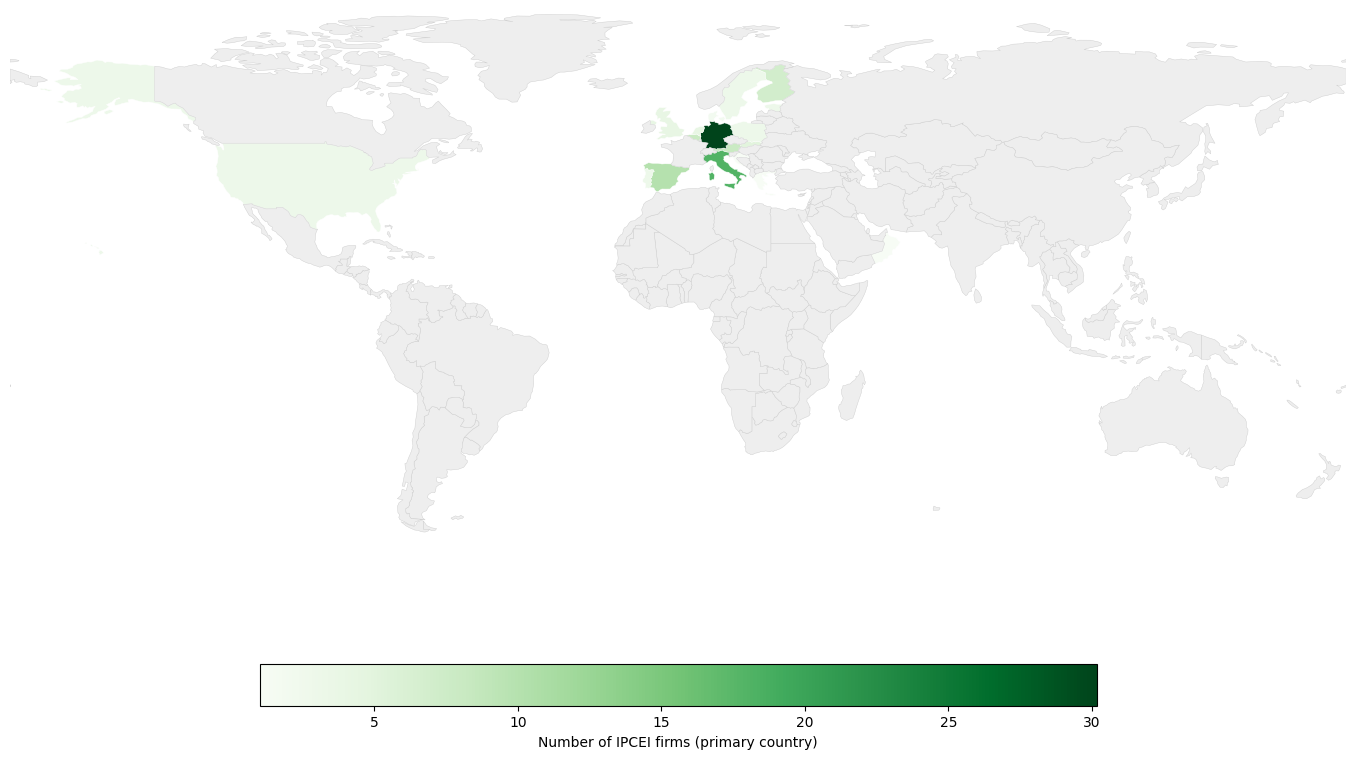

In [61]:
# ============================================================
# Map 1: Primary country of IPCEI firms
# ============================================================
primary_counts = (
    kept.dropna(subset=["primary_country"])
        .assign(iso3=lambda d: d["primary_country"].apply(iso2_to_iso3))
        .dropna(subset=["iso3"])
        .groupby("iso3", as_index=False)
        .agg(n_firms=("Linkedin_name", "nunique"))
)

cap = cap_at_quantile(primary_counts["n_firms"], 0.98)

world_primary = (
    world.merge(primary_counts, left_on="ISO_A3", right_on="iso3", how="left")
         .assign(n_firms_capped=lambda d: d["n_firms"].clip(upper=cap))
)

fig, ax = plt.subplots(figsize=(18, 10))
ax.set_facecolor("#f7f7f7")

world_primary.plot(
    column="n_firms_capped",
    ax=ax,
    cmap="Greens",
    linewidth=0.3,
    edgecolor="white",
    legend=True,
    missing_kwds={"color": "#eeeeee", "edgecolor": "#cccccc"},
    legend_kwds={
        "label": "Number of IPCEI firms (primary country)",
        "shrink": 0.6,
        "orientation": "horizontal",
    },
)

ax.axis("off")
ax.set_xlim([-180, 180])
ax.set_ylim([-60, 85])

save_fig(fig, "descriptives_raw", "firms_ipcei_countryprimary_map")
plt.show()

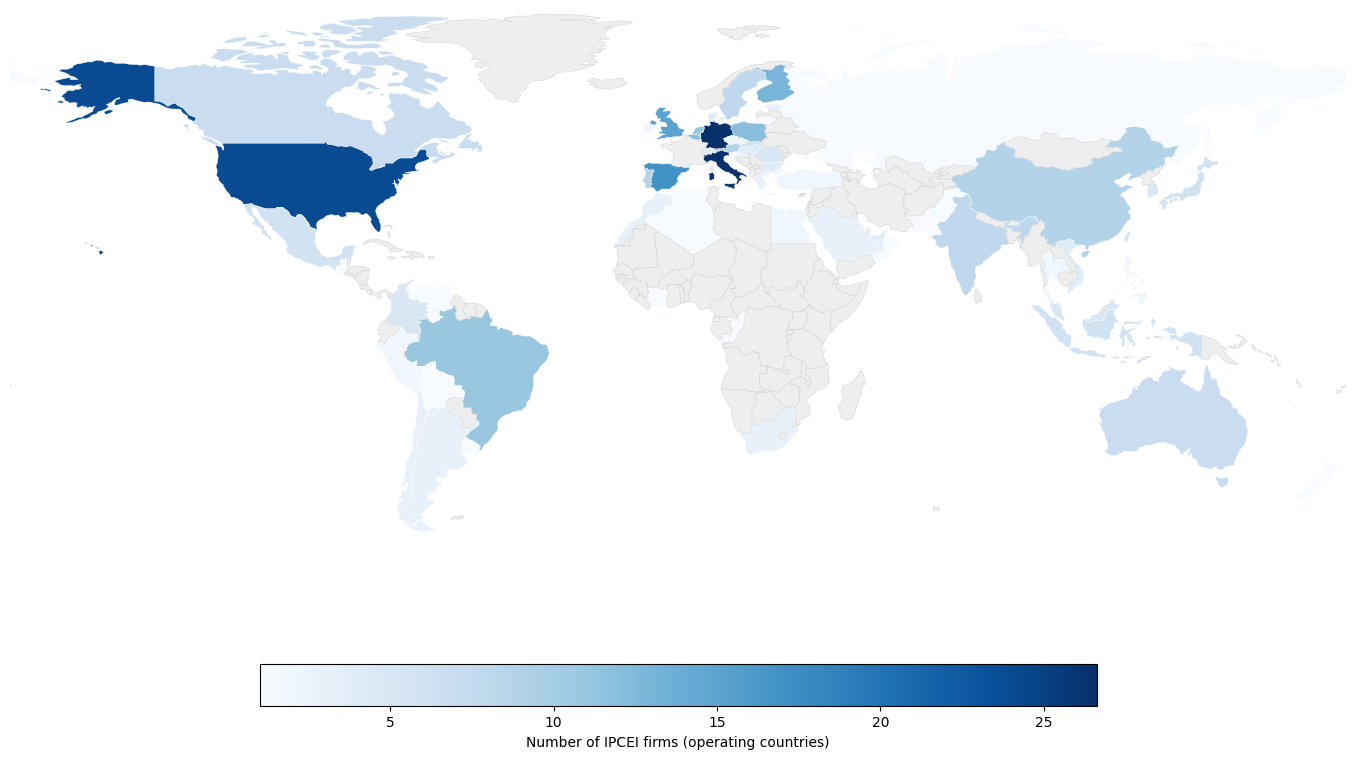

In [62]:
# ============================================================
# Map 2: Countries of operation (firm presence)
# ============================================================
presence = (
    kept[["Linkedin_name", "country_list"]]
        .explode("country_list")
        .rename(columns={"country_list": "iso2"})
        .assign(iso3=lambda d: d["iso2"].apply(iso2_to_iso3))
        .dropna(subset=["iso3"])
)

presence_counts = (
    presence.groupby("iso3", as_index=False)
            .agg(n_presences=("Linkedin_name", "nunique"))
)

cap = cap_at_quantile(presence_counts["n_presences"], 0.98)

world_presence = (
    world.merge(presence_counts, left_on="ISO_A3", right_on="iso3", how="left")
         .assign(n_presences_capped=lambda d: d["n_presences"].clip(upper=cap))
)

fig, ax = plt.subplots(figsize=(18, 10))
ax.set_facecolor("#f7f7f7")

world_presence.plot(
    column="n_presences_capped",
    ax=ax,
    cmap="Blues",
    linewidth=0.3,
    edgecolor="white",
    legend=True,
    missing_kwds={"color": "#eeeeee", "edgecolor": "#cccccc"},
    legend_kwds={
        "label": "Number of IPCEI firms (operating countries)",
        "shrink": 0.6,
        "orientation": "horizontal",
    },
)

ax.axis("off")
ax.set_xlim([-180, 180])
ax.set_ylim([-60, 85])

save_fig(fig, "descriptives_raw", "firms_ipcei_countryoperations_map")
plt.show()

Firm type, sector and industry

IPCEI type counts (firms):
Hydrogen    108
Battery      47
Both          5
Neither       0


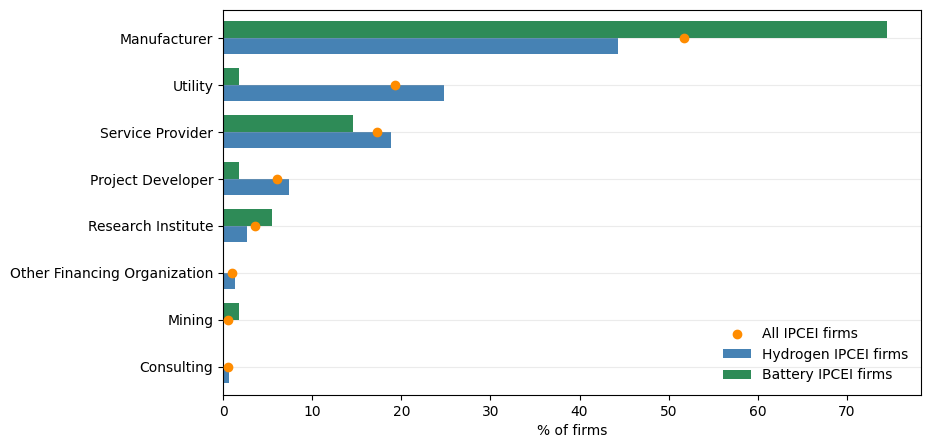

In [9]:
# ============================================================
# Firm type by IPCEI type (Hydrogen vs Battery) + overall dot
# ============================================================
fm = firm_master_ipcei.copy()

ipcei = (
    fm.loc[fm["treated_any"].fillna(0).astype(int) == 1,
           ["Linkedin_name", "firm_type", "ipcei_types"]]
      .dropna(subset=["firm_type", "ipcei_types"])
      .drop_duplicates("Linkedin_name")
      .copy()
)

# ------------------------------------------------------------
# Detect IPCEI type from ipcei_types (string field)
# ------------------------------------------------------------
types_lc = ipcei["ipcei_types"].astype("string").str.lower()

ipcei["is_hydrogen"] = types_lc.str.contains("hydrogen", na=False)
ipcei["is_battery"]  = types_lc.str.contains("battery", na=False)

# (optional) sanity check
print("IPCEI type counts (firms):")
print(pd.Series({
    "Hydrogen": ipcei.loc[ipcei["is_hydrogen"], "Linkedin_name"].nunique(),
    "Battery":  ipcei.loc[ipcei["is_battery"], "Linkedin_name"].nunique(),
    "Both":     ipcei.loc[ipcei["is_hydrogen"] & ipcei["is_battery"], "Linkedin_name"].nunique(),
    "Neither":  ipcei.loc[~(ipcei["is_hydrogen"] | ipcei["is_battery"]), "Linkedin_name"].nunique(),
}).to_string())

# ------------------------------------------------------------
# Expand firm_type roles
# ------------------------------------------------------------
roles = (
    ipcei[["Linkedin_name", "firm_type", "is_hydrogen", "is_battery"]]
    .assign(role=lambda d: d["firm_type"].astype("string").str.split(","))
    .explode("role")
)
roles["role"] = roles["role"].astype("string").str.strip()

def role_share(df):
    return df["role"].value_counts(normalize=True).mul(100)

share_h2   = role_share(roles.loc[roles["is_hydrogen"]])
share_batt = role_share(roles.loc[roles["is_battery"]])
share_all  = role_share(roles)

plot_df = pd.DataFrame({
    "Hydrogen IPCEI firms": share_h2,
    "Battery IPCEI firms": share_batt,
    "All IPCEI firms": share_all
}).fillna(0)

# sort by overall prevalence (dot)
plot_df = plot_df.sort_values("All IPCEI firms")

# ------------------------------------------------------------
# Plot: bars + overall dot
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 5))

plot_df[["Hydrogen IPCEI firms", "Battery IPCEI firms"]].plot(
    kind="barh",
    ax=ax,
    color=COLORS["two"],
    width=0.7
)

ypos = np.arange(len(plot_df))
ax.scatter(
    plot_df["All IPCEI firms"],
    ypos,
    color="darkorange",
    zorder=3,
    label="All IPCEI firms"
)

ax.set_xlabel("% of firms")
ax.set_ylabel("")
style_ax(ax)
ax.legend(frameon=False, loc="lower right")

save_fig(fig, "descriptives_raw", "firms_ipcei_firmtype_barchart")
plt.show()

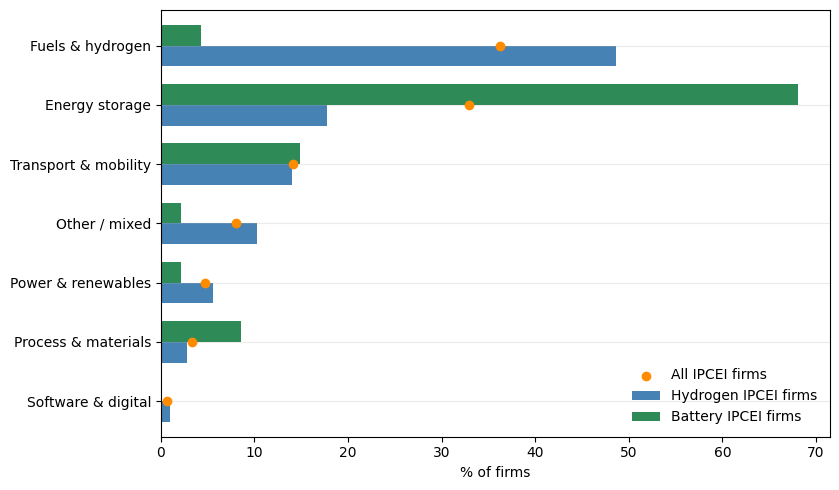

In [10]:
# ============================================================
# Sector buckets by IPCEI type
# ============================================================

fm = firm_master_ipcei.copy()

# ------------------------------------------------------------
# Construct IPCEI firm sample (INCLUDING sector)
# ------------------------------------------------------------
ipcei = (
    fm.loc[fm["treated_any"].fillna(0).astype(int) == 1,
           ["Linkedin_name", "sector", "ipcei_types"]]
      .dropna(subset=["sector", "ipcei_types"])
      .drop_duplicates("Linkedin_name")
      .copy()
)

# ------------------------------------------------------------
# Detect IPCEI type from ipcei_types
# ------------------------------------------------------------
types_lc = ipcei["ipcei_types"].astype("string").str.lower()

ipcei["is_hydrogen"] = types_lc.str.contains("hydrogen", na=False)
ipcei["is_battery"]  = types_lc.str.contains("battery", na=False)

# ------------------------------------------------------------
# Bucket sectors
# ------------------------------------------------------------
ipcei["sector_group"] = ipcei["sector"].apply(sector_bucket)

def share(df):
    return df["sector_group"].value_counts(normalize=True).mul(100)

share_h2   = share(ipcei.loc[ipcei["is_hydrogen"]])
share_batt = share(ipcei.loc[ipcei["is_battery"]])
share_all  = share(ipcei)

plot_df = pd.DataFrame({
    "Hydrogen IPCEI firms": share_h2,
    "Battery IPCEI firms":  share_batt,
    "All IPCEI firms":      share_all,
}).fillna(0)

# Sort by overall prevalence
plot_df = plot_df.sort_values("All IPCEI firms")

# ------------------------------------------------------------
# Plot: bars + overall dot
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8.5, 5))

plot_df[["Hydrogen IPCEI firms", "Battery IPCEI firms"]].plot(
    kind="barh",
    ax=ax,
    color=COLORS["two"],
    width=0.7
)

ypos = np.arange(len(plot_df))

ax.scatter(
    plot_df["All IPCEI firms"],
    ypos,
    color=COLORS["three"][2],   # same darkorange as elsewhere
    zorder=3,
    label="All IPCEI firms"
)

ax.set_xlabel("% of firms")
ax.set_ylabel("")

style_ax(ax)
ax.legend(frameon=False, loc="lower right")

plt.tight_layout()
save_fig(fig, "descriptives_raw", "firms_ipcei_sectorbuckets_barchart")
plt.show()

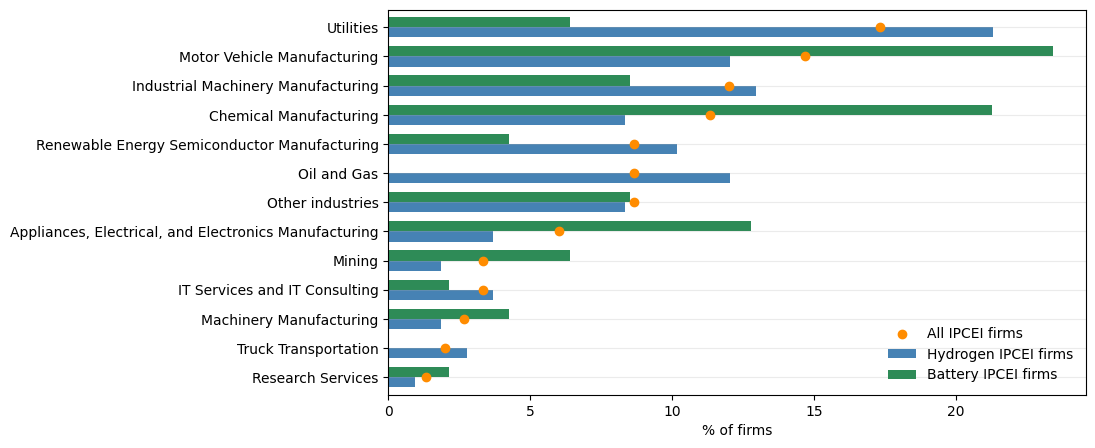

In [11]:
# ============================================================
# Industry by IPCEI type (Hydrogen vs Battery)
# ============================================================
fm = firm_master_ipcei.copy()

ipcei = (
    fm.loc[fm["treated_any"].fillna(0).astype(int) == 1,
           ["Linkedin_name", "industry", "ipcei_types"]]
      .dropna(subset=["industry", "ipcei_types"])
      .drop_duplicates("Linkedin_name")
      .copy()
)

# IPCEI type flags
types_lc = ipcei["ipcei_types"].astype("string").str.lower()
ipcei["is_hydrogen"] = types_lc.str.contains("hydrogen", na=False)
ipcei["is_battery"]  = types_lc.str.contains("battery", na=False)

def share(df):
    return df["industry"].value_counts(normalize=True).mul(100)

share_h2   = share(ipcei.loc[ipcei["is_hydrogen"]])
share_batt = share(ipcei.loc[ipcei["is_battery"]])
share_all  = share(ipcei)

plot_df = pd.DataFrame({
    "Hydrogen IPCEI firms": share_h2,
    "Battery IPCEI firms":  share_batt,
    "All IPCEI firms":      share_all,
}).fillna(0)

# keep top N industries by overall prevalence
TOP_N = 12
if len(plot_df) > TOP_N:
    top = plot_df.sort_values("All IPCEI firms").iloc[-TOP_N:]
    other = plot_df.drop(top.index).sum()
    plot_df = pd.concat([top, other.to_frame(name="Other industries").T])

plot_df = plot_df.sort_values("All IPCEI firms")

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 5))

plot_df[["Hydrogen IPCEI firms", "Battery IPCEI firms"]].plot(
    kind="barh",
    ax=ax,
    color=COLORS["two"],
    width=0.7
)

ypos = np.arange(len(plot_df))
ax.scatter(
    plot_df["All IPCEI firms"],
    ypos,
    color=COLORS["three"][2],  # same orange as before
    zorder=3,
    label="All IPCEI firms"
)

ax.set_xlabel("% of firms")
ax.set_ylabel("")
style_ax(ax)
ax.legend(frameon=False, loc="lower right")

save_fig(fig, "descriptives_raw", "firms_ipcei_industry_barchart")
plt.show()

Size and age

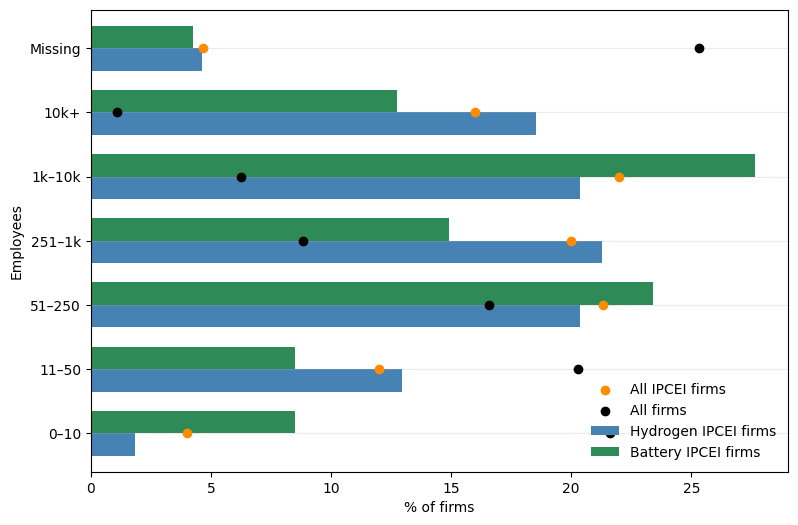

In [12]:
# ============================================================
# Staff count distribution by IPCEI type
# ============================================================
fm = firm_master_ipcei.copy()

# one row per firm
base = (
    fm.drop_duplicates("Linkedin_name")
      .copy()
)

# numeric staffCount
base["staffCount_num"] = pd.to_numeric(base["staffCount"], errors="coerce")

# IPCEI type flags
types_lc = base["ipcei_types"].astype("string").str.lower()
base["is_hydrogen"] = types_lc.str.contains("hydrogen", na=False)
base["is_battery"]  = types_lc.str.contains("battery", na=False)

# ------------------------------------------------------------
# Staff count bins
# ------------------------------------------------------------
bins = [0, 10, 50, 250, 1000, 10000, np.inf]
labels = ["0–10", "11–50", "51–250", "251–1k", "1k–10k", "10k+"]

base["staff_bin"] = pd.cut(
    base["staffCount_num"],
    bins=bins,
    labels=labels,
    right=True,
    include_lowest=True
)

# add Missing
base["staff_bin"] = base["staff_bin"].cat.add_categories(["Missing"]).fillna("Missing")

# ------------------------------------------------------------
# Shares
# ------------------------------------------------------------
def share(df):
    return df["staff_bin"].value_counts(normalize=True).mul(100)

treated = base.loc[base["treated_any"].fillna(0).astype(int) == 1]

share_h2   = share(treated.loc[treated["is_hydrogen"]])
share_batt = share(treated.loc[treated["is_battery"]])
share_ipcei = share(treated)
share_all   = share(base)

# align bins
order = labels + ["Missing"]
plot_df = pd.DataFrame({
    "Hydrogen IPCEI firms": share_h2,
    "Battery IPCEI firms":  share_batt,
    "All IPCEI firms":      share_ipcei,
    "All firms":      share_all,
}).reindex(order).fillna(0)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 6))

# bars: Hydrogen & Battery
plot_df[["Hydrogen IPCEI firms", "Battery IPCEI firms"]].plot(
    kind="barh",
    ax=ax,
    color=COLORS["two"],
    width=0.7
)

ypos = np.arange(len(plot_df))

# dot: all IPCEI
ax.scatter(
    plot_df["All IPCEI firms"],
    ypos,
    color=COLORS["three"][2],  # orange
    zorder=3,
    label="All IPCEI firms"
)

# dot: all firms
ax.scatter(
    plot_df["All firms"],
    ypos,
    color="black",
    zorder=3,
    label="All firms"
)

ax.set_xlabel("% of firms")
ax.set_ylabel("Employees")
style_ax(ax)
ax.legend(frameon=False, loc="lower right")

save_fig(fig, "descriptives_raw", "firms_all_staffcount_barchart")
plt.show()

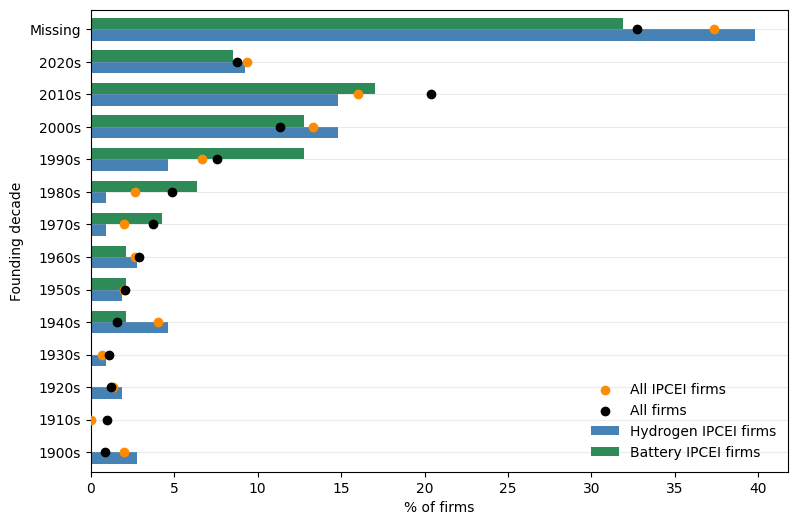

In [13]:
# ============================================================
# Founding decade distribution by IPCEI type
# ============================================================
fm = firm_master_ipcei.copy()

# one row per firm
base = (
    fm.drop_duplicates("Linkedin_name")
      .copy()
)

# IPCEI type flags
types_lc = base["ipcei_types"].astype("string").str.lower()
base["is_hydrogen"] = types_lc.str.contains("hydrogen", na=False)
base["is_battery"]  = types_lc.str.contains("battery", na=False)

# ------------------------------------------------------------
# Shares by founding decade
# ------------------------------------------------------------
treated = base.loc[base["treated_any"].fillna(0).astype(int) == 1]

share_h2    = decade_shares(
    treated.loc[treated["is_hydrogen"]],
    start=1900, end=2031, step=10,
)
share_batt  = decade_shares(
    treated.loc[treated["is_battery"]],
    start=1900, end=2031, step=10,
)
share_ipcei = decade_shares(
    treated,
    start=1900, end=2031, step=10,
)
share_all   = decade_shares(
    base,
    start=1900, end=2031, step=10,
)

# align decades
plot_df = pd.DataFrame({
    "Hydrogen IPCEI firms": share_h2,
    "Battery IPCEI firms":  share_batt,
    "All IPCEI firms":      share_ipcei,
    "All firms":      share_all,
}).dropna(how="all")

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 6))

# bars: Hydrogen & Battery
plot_df[["Hydrogen IPCEI firms", "Battery IPCEI firms"]].plot(
    kind="barh",
    ax=ax,
    color=COLORS["two"],
    width=0.7
)

ypos = np.arange(len(plot_df))

# dot: all IPCEI
ax.scatter(
    plot_df["All IPCEI firms"],
    ypos,
    color=COLORS["three"][2],  # orange
    zorder=3,
    label="All IPCEI firms"
)

# dot: all firms
ax.scatter(
    plot_df["All firms"],
    ypos,
    color="black",
    zorder=3,
    label="All firms"
)

ax.set_xlabel("% of firms")
ax.set_ylabel("Founding decade")
style_ax(ax)
ax.legend(frameon=False, loc="lower right")

save_fig(fig, "descriptives_raw", "firms_all_foundingdecade_barchart")
plt.show()

#### 4. Plot firm collaborations

Intensity

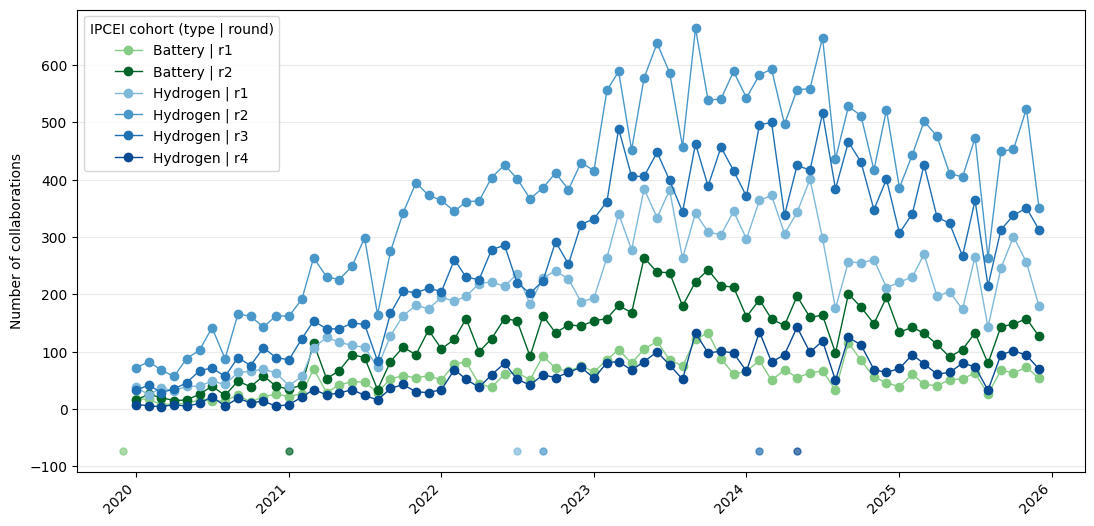

In [8]:
# ============================================================
# Collaboration intensity by cohort over time
# ============================================================

# ------------------------------------------------------------
# 0) Prep events: firm → cohort + event month
# ------------------------------------------------------------
ev = firm_master_ipcei_events.copy()

ev["ipcei_post_date"] = to_dt(ev["ipcei_post_date"])
ev = ev.dropna(subset=[
    "Linkedin_name", "ipcei_post_date", "ipcei_type", "ipcei_round"
]).copy()

ev["event_month"] = to_month(ev["ipcei_post_date"])
ev["cohort"] = (
    ev["ipcei_type"].astype("string").str.strip()
    + " | r"
    + ev["ipcei_round"].astype("string").str.strip()
)

# one rug point per month × cohort
ev_rug = ev.drop_duplicates(subset=["event_month", "cohort"]).copy()

# firm → cohort mapping (a firm can appear in multiple cohorts)
firm_to_cohorts = (
    ev[["Linkedin_name", "cohort"]]
    .drop_duplicates()
)

cohorts = sorted(firm_to_cohorts["cohort"].unique())

# ------------------------------------------------------------
# 1) Prep partnerships: add month + restrict window
# ------------------------------------------------------------
p = partnership_master_ipcei.copy()

p["post_date"] = to_dt(p["post_date"])
p = p.loc[p["post_date"].ge(PLOT_START)].copy()
p["month"] = to_month(p["post_date"])

for c in ["source", "target", "collaboration_id"]:
    if c not in p.columns:
        raise KeyError(f"Missing required column: {c}")

# ------------------------------------------------------------
# 2) Expand partnerships to cohort exposure
# ------------------------------------------------------------
src = firm_to_cohorts.rename(
    columns={"Linkedin_name": "source", "cohort": "cohort"}
)
tgt = firm_to_cohorts.rename(
    columns={"Linkedin_name": "target", "cohort": "cohort"}
)

p_src = p.merge(src, on="source", how="left")
p_tgt = p.merge(tgt, on="target", how="left")

p_long = pd.concat(
    [
        p_src[["month", "collaboration_id", "cohort"]],
        p_tgt[["month", "collaboration_id", "cohort"]],
    ],
    ignore_index=True
)

# drop non-exposed & avoid double counting
p_long = (
    p_long
    .dropna(subset=["cohort"])
    .drop_duplicates(subset=["month", "collaboration_id", "cohort"])
)

monthly_by_cohort = (
    p_long.groupby(["cohort", "month"])["collaboration_id"]
          .nunique()
          .reset_index(name="n_collabs")
)

# ------------------------------------------------------------
# 3) Colors (unchanged logic: Blues = H2, Greens = Battery)
# ------------------------------------------------------------
battery_cohorts  = [c for c in cohorts if c.lower().startswith("battery")]
hydrogen_cohorts = [c for c in cohorts if c.lower().startswith("hydrogen")]

color_map = {}
color_map.update(round_colors("battery",  battery_cohorts))
color_map.update(round_colors("hydrogen", hydrogen_cohorts))

# ------------------------------------------------------------
# 4) Plot: cohort lines + cohort rug
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(13, 6))

# lines
for c in cohorts:
    sub = (
        monthly_by_cohort
        .loc[monthly_by_cohort["cohort"] == c]
        .sort_values("month")
    )
    ax.plot(
        sub["month"],
        sub["n_collabs"],
        marker="o",
        linewidth=1,
        color=color_map.get(c),
        label=c.capitalize(),
    )

# rug (event timing)
ymin, ymax = ax.get_ylim()
rug_y = ymin - 0.06 * (ymax - ymin)

for c in cohorts:
    sub = ev_rug.loc[ev_rug["cohort"] == c]
    if len(sub) == 0:
        continue
    ax.scatter(
        sub["event_month"],
        [rug_y] * len(sub),
        s=25,
        alpha=0.7,
        color=color_map.get(c),
    )

ax.set_ylim(rug_y - 0.05 * (ymax - ymin), ymax)

#ax.set_xlabel("Year")
ax.set_ylabel("Number of collaborations")
style_ax(ax)
plt.xticks(rotation=45, ha="right")

# legend cap
MAX_LEGEND = 12
handles, labels = ax.get_legend_handles_labels()
if len(labels) > MAX_LEGEND:
    ax.legend(
        handles[:MAX_LEGEND],
        labels[:MAX_LEGEND] + [f"+{len(labels) - MAX_LEGEND} more"],
        title="Cohort (type | round)",
        loc="upper left",
        frameon=True,
    )
else:
    ax.legend(
        title="IPCEI cohort (type | round)",
        loc="upper left",
        frameon=True,
    )

save_fig(fig, "descriptives_raw", "collaborations_ipcei_intensity_lineplot")
plt.show()

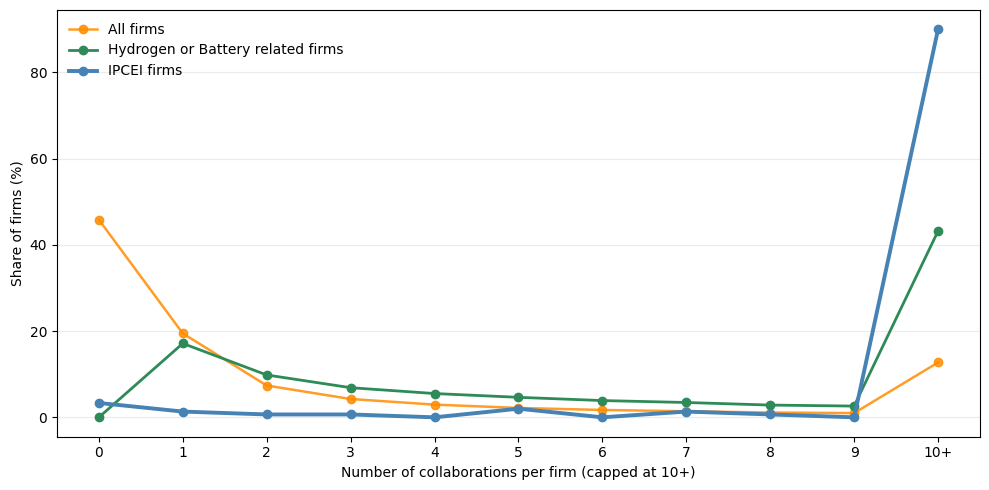

In [14]:
# ============================================================
# Collaboration intensity distribution
# ============================================================

fm = firm_master_ipcei.copy()
p = partnership_master_ipcei.copy()

# ------------------------------------------------------------
# 1) Compute unique collaboration counts per firm
# ------------------------------------------------------------

collabs = p[["source", "target", "collaboration_id"]].copy()

long = pd.concat([
    collabs.rename(columns={"source": "Linkedin_name"})[
        ["Linkedin_name", "collaboration_id"]
    ],
    collabs.rename(columns={"target": "Linkedin_name"})[
        ["Linkedin_name", "collaboration_id"]
    ],
], ignore_index=True)

firm_counts = (
    long.groupby("Linkedin_name")["collaboration_id"]
        .nunique()
        .reset_index(name="n_collabs")
)

df = fm.merge(firm_counts, on="Linkedin_name", how="left")
df["n_collabs"] = df["n_collabs"].fillna(0)

# ------------------------------------------------------------
# 2) Cap at 10 collaborations (stable visual)
# ------------------------------------------------------------

cap = 10
df["n_collabs_capped"] = df["n_collabs"].clip(upper=cap)

# ------------------------------------------------------------
# 3) Construct masks
# ------------------------------------------------------------

# IPCEI firms
mask_ipcei = df["treated_any"].fillna(0).astype(int) == 1

# Energy-active firms (from collaboration activity!)
mask_energy_collab = (
    pd.to_numeric(p.get("Hydrogen"), errors="coerce").fillna(0).eq(1)
    | pd.to_numeric(p.get("Battery"), errors="coerce").fillna(0).eq(1)
)

energy_collabs = p.loc[mask_energy_collab, ["source", "target"]]

energy_firms = set(energy_collabs["source"]).union(
    set(energy_collabs["target"])
)

mask_energy = df["Linkedin_name"].isin(energy_firms)

# All firms
mask_all = pd.Series(True, index=df.index)

# ------------------------------------------------------------
# 4) Compute percent distributions
# ------------------------------------------------------------

dist_ipcei  = pct_dist(df, mask_ipcei, cap)
dist_energy = pct_dist(df, mask_energy, cap)
dist_all    = pct_dist(df, mask_all, cap)

# ------------------------------------------------------------
# 5) Plot
# ------------------------------------------------------------

x = np.arange(0, cap + 1)
x_labels = [str(i) for i in range(0, cap)] + [f"{cap}+"]


fig, ax = plt.subplots(figsize=(10, 5))

# Plot all first (background)
ax.plot(
    x, dist_all.values,
    marker="o", linewidth=1.8,
    color=COLORS["three"][2],
    alpha=0.85,
    label="All firms",
    zorder=1
)

# Plot energy-active
ax.plot(
    x, dist_energy.values,
    marker="o", linewidth=2.0,
    color=COLORS["three"][1],
    label="Hydrogen or Battery related firms",
    zorder=2
)

# Plot IPCEI last (most prominent)
ax.plot(
    x, dist_ipcei.values,
    marker="o", linewidth=2.8,
    color=COLORS["three"][0],
    label="IPCEI firms",
    zorder=3
)

ax.set_xticks(x)
ax.set_xticklabels(x_labels)

ax.set_xlabel("Number of collaborations per firm (capped at 10+)")
ax.set_ylabel("Share of firms (%)")

style_ax(ax)
ax.legend(frameon=False)

plt.tight_layout()
save_fig(fig, "descriptives_raw", "collaborations_all_distribution_lineplot")
plt.show()

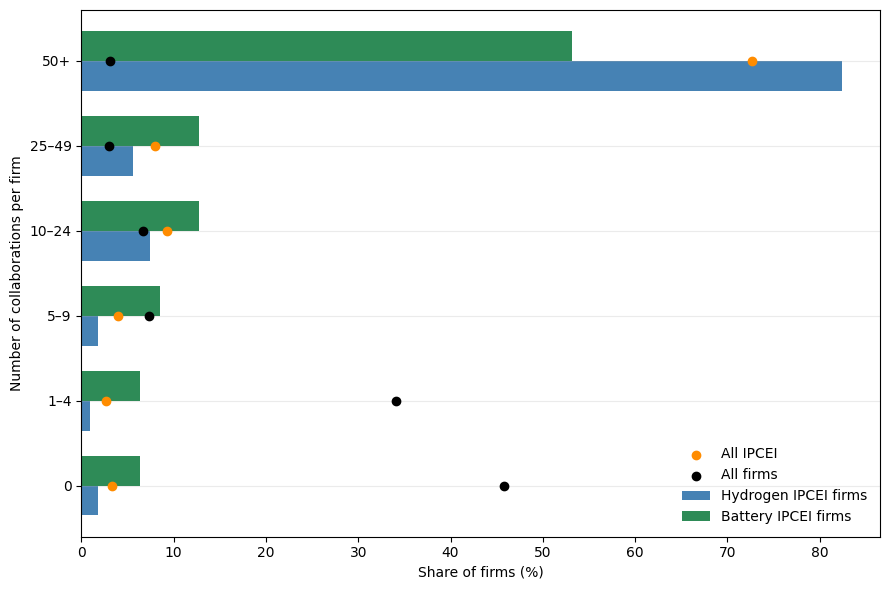

In [15]:
# ============================================================
# Collaboration intensity distribution by IPCEI type
# ============================================================

fm = firm_master_ipcei.copy()
p = partnership_master_ipcei.copy()

# one row per firm
base = fm.drop_duplicates("Linkedin_name").copy()

# ------------------------------------------------------------
# 1) Compute unique collaboration counts per firm
# ------------------------------------------------------------

collabs = p[["source", "target", "collaboration_id"]].copy()

long = pd.concat([
    collabs.rename(columns={"source": "Linkedin_name"})[["Linkedin_name", "collaboration_id"]],
    collabs.rename(columns={"target": "Linkedin_name"})[["Linkedin_name", "collaboration_id"]],
], ignore_index=True)

firm_counts = (
    long.groupby("Linkedin_name")["collaboration_id"]
        .nunique()
        .reset_index(name="n_collabs")
)

base = base.merge(firm_counts, on="Linkedin_name", how="left")
base["n_collabs"] = base["n_collabs"].fillna(0).astype(int)

# ------------------------------------------------------------
# 2) IPCEI type flags
# ------------------------------------------------------------

types_lc = base["ipcei_types"].astype("string").str.lower()
base["is_hydrogen"] = types_lc.str.contains("hydrogen", na=False)
base["is_battery"]  = types_lc.str.contains("battery",  na=False)

# ------------------------------------------------------------
# 3) Collaboration buckets
# ------------------------------------------------------------

bins   = [0, 1, 5, 10, 25, 50, np.inf]
labels = ["0", "1–4", "5–9", "10–24", "25–49", "50+"]

base["collab_bin"] = pd.cut(
    base["n_collabs"],
    bins=bins,
    labels=labels,
    right=False,
)

# ------------------------------------------------------------
# 4) Shares
# ------------------------------------------------------------

def share(df):
    return df["collab_bin"].value_counts(normalize=True).mul(100)

treated = base.loc[base["treated_any"].fillna(0).astype(int) == 1]

share_h2    = share(treated.loc[treated["is_hydrogen"]])
share_batt  = share(treated.loc[treated["is_battery"]])
share_ipcei = share(treated)
share_all   = share(base)

# align bins
plot_df = pd.DataFrame({
    "Hydrogen IPCEI firms": share_h2,
    "Battery IPCEI firms":  share_batt,
    "All IPCEI firms":      share_ipcei,
    "All firms":      share_all,
}).reindex(labels).fillna(0)

# ------------------------------------------------------------
# 5) Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 6))

# bars: Hydrogen & Battery
plot_df[["Hydrogen IPCEI firms", "Battery IPCEI firms"]].plot(
    kind="barh",
    ax=ax,
    color=COLORS["two"],
    width=0.7,
)

ypos = np.arange(len(plot_df))

# dot: all IPCEI
ax.scatter(
    plot_df["All IPCEI firms"],
    ypos,
    color=COLORS["three"][2],
    zorder=3,
    label="All IPCEI",
)

# dot: all firms
ax.scatter(
    plot_df["All firms"],
    ypos,
    color="black",
    zorder=3,
    label="All firms",
)

ax.set_xlabel("Share of firms (%)")
ax.set_ylabel("Number of collaborations per firm")
style_ax(ax)
ax.legend(frameon=False, loc="lower right")

plt.tight_layout()
save_fig(fig, "descriptives_raw", "collaborations_all_distribution_barchart")
plt.show()

Intensity around event time

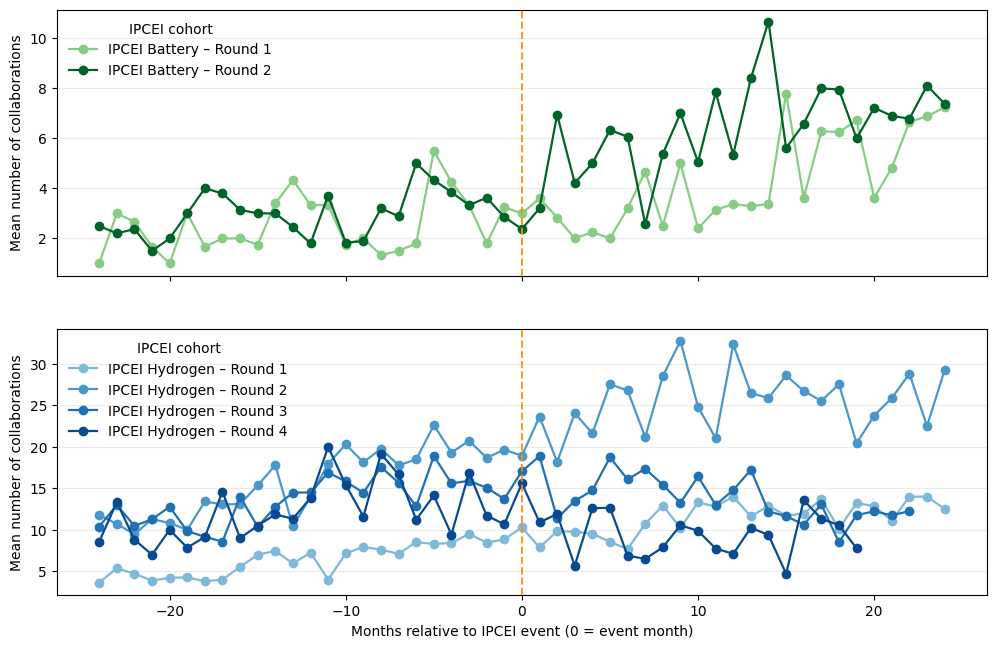

In [16]:
# ============================================================
# Collaboration dynamics around IPCEI events (by cohort)
# Not normalized – mean collaborations per event
# ============================================================

WINDOW = 24

# ------------------------------------------------------------
# 1) Restrict to symmetric event window
# ------------------------------------------------------------
ees = event_panel.copy()
ees = ees.loc[ees["event_time"].between(-WINDOW, WINDOW)].copy()

assert ees["event_id"].nunique() > 1, "Only one event detected — something is wrong."

# ------------------------------------------------------------
# 2) Count collaborations per event × event_time
# ------------------------------------------------------------
event_time_counts = (
    ees.groupby(
        ["event_id", "ipcei_type", "ipcei_round", "event_time"],
        as_index=False
    )["collaboration_id"]
    .nunique()
    .rename(columns={"collaboration_id": "n_collabs"})
)

# ------------------------------------------------------------
# 3) Average across events (cohort × event_time)
# ------------------------------------------------------------
g = (
    event_time_counts
    .groupby(
        ["ipcei_type", "ipcei_round", "event_time"],
        as_index=False
    )["n_collabs"]
    .mean()
)

# ------------------------------------------------------------
# 4) Plot by technology (Hydrogen / Battery)
# ------------------------------------------------------------
types = sorted(
    g["ipcei_type"].dropna().unique(),
    key=lambda x: str(x).lower()
)

fig, axes = plt.subplots(
    len(types),
    1,
    figsize=(12, 3.8 * len(types)),
    sharex=True
)

if len(types) == 1:
    axes = [axes]

for ax, t in zip(axes, types):
    sub = g[g["ipcei_type"] == t].copy()
    rounds = sorted(sub["ipcei_round"].dropna().unique())

    # round-specific shades (Greens for battery, Blues for hydrogen)
    colors = round_colors(t, rounds)

    for r in rounds:
        sr = (
            sub[sub["ipcei_round"] == r]
            .sort_values("event_time")
        )

        ax.plot(
            sr["event_time"],
            sr["n_collabs"],
            marker="o",
            linewidth=1.6,
            color=colors[r],
            label=f"IPCEI {t.capitalize()} – Round {int(r)}",
        )

    # event time
    ax.axvline(0, linestyle="--", linewidth=1.4, color="darkorange", alpha=0.9)

    ax.set_ylabel("Mean number of collaborations")
    style_ax(ax)
    ax.legend(title="IPCEI cohort", frameon=False)

axes[-1].set_xlabel("Months relative to IPCEI event (0 = event month)")

save_fig(
    fig,
    "descriptives_raw",
    "collaborations_ipcei_eventintensity_lineplot"
)

plt.show()

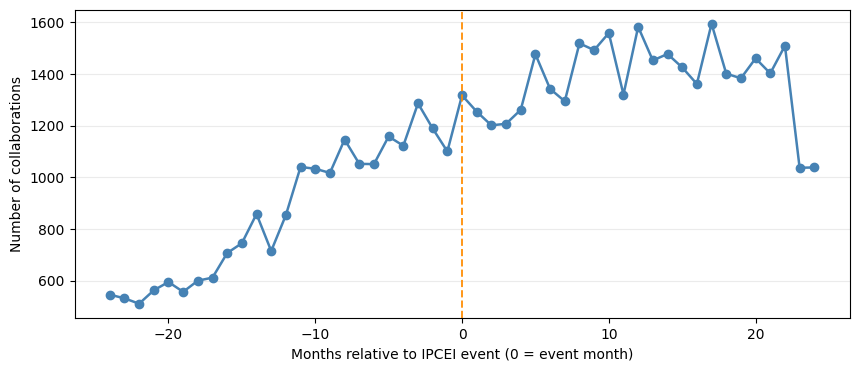

In [17]:
# ------------------------------------------------------------
# Collaborations around IPCEI events: overall (not normalized)
# ------------------------------------------------------------

WINDOW = 24  # keep consistent with other event-time plots

ees = event_panel.copy()

# keep only event-time window (assumes event_time exists in event_panel)
ees = ees.loc[ees["event_time"].between(-WINDOW, WINDOW)].copy()

# overall unique collaborations by relative month
g = (
    ees.groupby("event_time")["collaboration_id"]
       .nunique()
       .reset_index(name="n_collabs")
       .sort_values("event_time")
)

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(g["event_time"], g["n_collabs"], marker="o", linewidth=1.8, color="steelblue")

ax.axvline(0, linestyle="--", linewidth=1.4, color="darkorange", alpha=0.9)

ax.set_xlabel("Months relative to IPCEI event (0 = event month)")
ax.set_ylabel("Number of collaborations")

style_ax(ax)

save_fig(fig, "descriptives_raw", "collaborations_ipcei_eventintesnity2_lineplot")
plt.show()

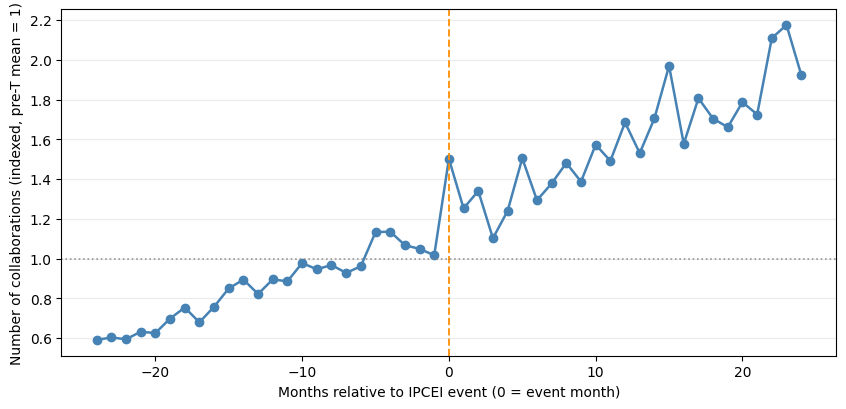

In [19]:
# ------------------------------------------------------------
# Collaborations around IPCEI events: overall (normalized)
# ------------------------------------------------------------

WINDOW = 24
PRE_WINDOW = (-12, -1)

ees = event_panel.copy()

# safety: require event_time + event_id + collaboration_id
need = {"event_id", "event_time", "collaboration_id"}
missing = need - set(ees.columns)
if missing:
    raise KeyError(f"event_panel missing columns: {missing}")

# restrict to event window
ees = ees.loc[ees["event_time"].between(-WINDOW, WINDOW)].copy()

# if n_collabs not already present, construct it at event_id × event_time level
if "n_collabs" not in ees.columns:
    ees = (
        ees.groupby(["event_id", "event_time"], as_index=False)["collaboration_id"]
           .nunique()
           .rename(columns={"collaboration_id": "n_collabs"})
    )

# ------------------------------------------------------------
# 1) Baseline: pre-event mean per event
# ------------------------------------------------------------
baseline = (
    ees.loc[ees["event_time"].between(*PRE_WINDOW)]
       .groupby("event_id")["n_collabs"]
       .mean()
       .rename("baseline")
)

# ------------------------------------------------------------
# 2) Normalize by event-specific baseline
# ------------------------------------------------------------
norm = ees.merge(baseline, on="event_id", how="inner")

norm["n_collabs_norm"] = norm["n_collabs"] / norm["baseline"]

# ------------------------------------------------------------
# 3) Average across events by relative month
# ------------------------------------------------------------
plot_df = (
    norm.groupby("event_time")["n_collabs_norm"]
        .mean()
        .reset_index()
        .sort_values("event_time")
)

# ------------------------------------------------------------
# 4) Plot
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 4.5))

ax.plot(
    plot_df["event_time"],
    plot_df["n_collabs_norm"],
    marker="o",
    linewidth=1.8,
    color="steelblue",
)

ax.axvline(0, linestyle="--", linewidth=1.4, color="darkorange", alpha=0.9)
ax.axhline(1, linestyle=":", linewidth=1.2, color="grey", alpha=0.8)

ax.set_xlabel("Months relative to IPCEI event (0 = event month)")
ax.set_ylabel("Number of collaborations (indexed, pre-T mean = 1)")

style_ax(ax)
save_fig(fig, "descriptives_raw", "collaborations_ipcei_eventintensity_normalized_lineplot")

plt.show()

Cross-border

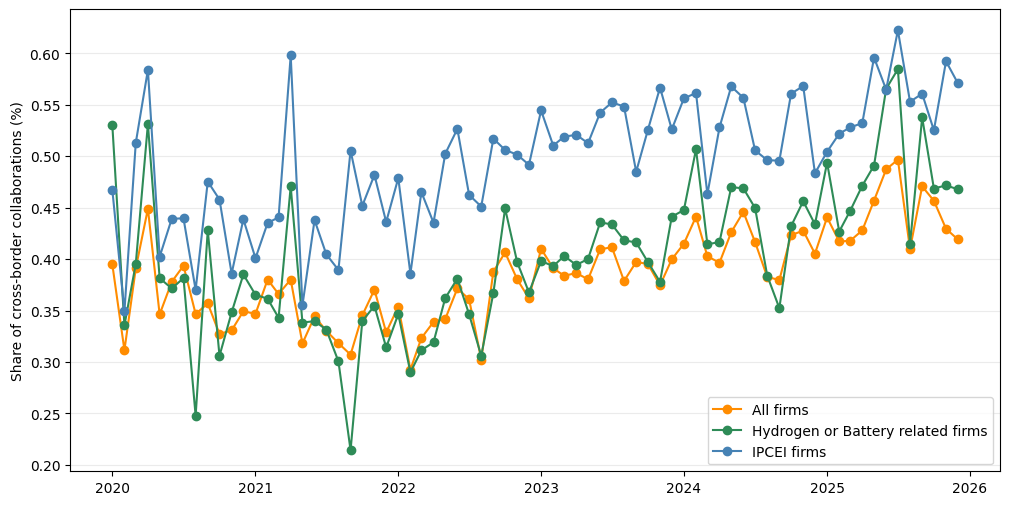

In [20]:
# ============================================================
# Cross-border collaboration share over time
# ============================================================

p = partnership_master_ipcei.copy()
fm = firm_master_ipcei.copy()

# dates
p["post_date"] = to_dt(p["post_date"])
p = p.dropna(subset=["post_date"]).copy()
p["month"] = to_month(p["post_date"])

# firm → country set
for c in ["countries", "primary_country", "hq_country"]:
    if c in fm.columns:
        country_col = c
        break
else:
    raise KeyError("No country column found in firm_master_ipcei")

firm_country = (
    fm[["Linkedin_name", country_col]]
    .drop_duplicates("Linkedin_name")
    .copy()
)
firm_country["country_set"] = firm_country[country_col].apply(parse_iso2_list)
country_map = dict(zip(firm_country["Linkedin_name"], firm_country["country_set"]))

# attach endpoint country sets
p["source_country_set"] = p["source"].map(country_map).apply(
    lambda x: x if isinstance(x, set) else set()
)
p["target_country_set"] = p["target"].map(country_map).apply(
    lambda x: x if isinstance(x, set) else set()
)

p["cross_border"] = [
    cross_border(a, b)
    for a, b in zip(p["source_country_set"], p["target_country_set"])
]

# masks
mask_all = pd.Series(True, index=p.index)

mask_energy = pd.Series(False, index=p.index)
for tech in ["Hydrogen", "Battery"]:
    if tech in p.columns:
        mask_energy |= pd.to_numeric(p[tech], errors="coerce").fillna(0).eq(1)

mask_ipcei = (
    pd.to_numeric(p["any_treated"], errors="coerce").fillna(0).eq(1)
    if "any_treated" in p.columns
    else pd.Series(False, index=p.index)
)

series = pd.concat(
    [
        monthly_rate(p, mask_ipcei,  "IPCEI firms"),
        monthly_rate(p, mask_energy, "Hydrogen or Battery related firms"),
        monthly_rate(p, mask_all,    "All firms"),
    ],
    ignore_index=True,
).loc[lambda d: d["month"] >= PLOT_START]

# plot
fig, ax = plt.subplots(figsize=(12, 6))

COLOR_MAP = {
    "IPCEI firms": "steelblue",
    "Hydrogen or Battery related firms": "seagreen",
    "All firms": "darkorange",
}

for name, sub in series.groupby("series"):
    sub = sub.sort_values("month")
    ax.plot(
        sub["month"],
        sub["rate"],
        marker="o",
        linewidth=1.5,
        color=COLOR_MAP[name],
        label=name,
    )

ax.set_ylabel("Share of cross-border collaborations (%)")
#ax.set_xlabel("Year")
style_ax(ax)
ax.legend()

save_fig(fig, "descriptives_raw", "collaborations_all_crossborder_lineplot")
plt.show()

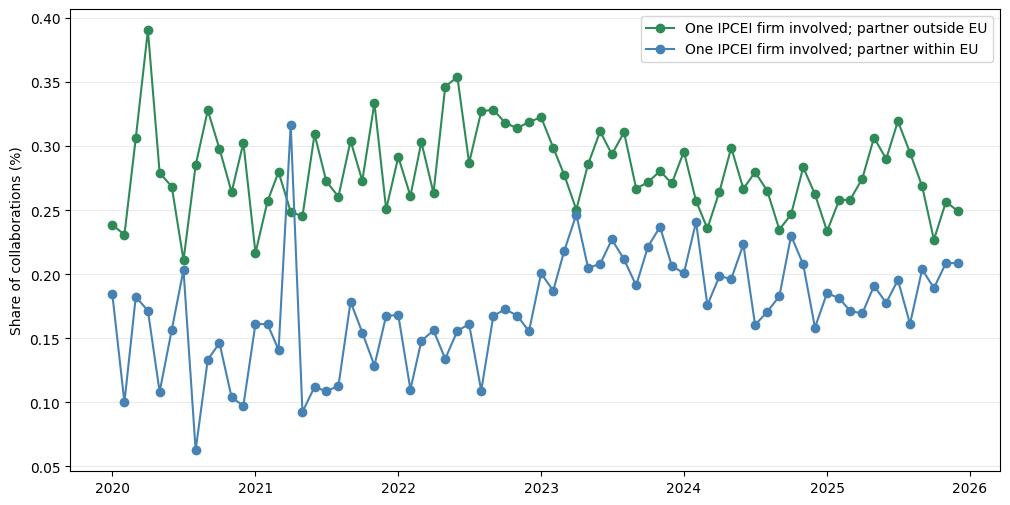

In [22]:
# ============================================================
# EU-internal vs non-EU collaborations
# ============================================================

p = partnership_master_ipcei.copy()
fm = firm_master_ipcei.copy()

# dates
p["post_date"] = to_dt(p["post_date"])
p = p.dropna(subset=["post_date"]).copy()
p["month"] = to_month(p["post_date"])

# firm → country set
for c in ["countries", "primary_country", "hq_country"]:
    if c in fm.columns:
        country_col = c
        break
else:
    raise KeyError("No country column found in firm_master_ipcei")

firm_country = (
    fm[["Linkedin_name", country_col]]
    .drop_duplicates("Linkedin_name")
    .copy()
)
firm_country["country_set"] = firm_country[country_col].apply(parse_iso2_list)
country_map = dict(zip(firm_country["Linkedin_name"], firm_country["country_set"]))

# attach endpoint country sets
p["source_country_set"] = p["source"].map(country_map).apply(
    lambda x: x if isinstance(x, set) else set()
)
p["target_country_set"] = p["target"].map(country_map).apply(
    lambda x: x if isinstance(x, set) else set()
)

# Filter to IPCEI collaborations
mask_ipcei = (
    pd.to_numeric(p["any_treated"], errors="coerce").fillna(0).eq(1)
    if "any_treated" in p.columns
    else pd.Series(False, index=p.index)
)

p_ipcei = p[mask_ipcei].copy()

# Classify each collaboration
p_ipcei["collab_type"] = [
    classify_collaboration(a, b)
    for a, b in zip(p_ipcei["source_country_set"], p_ipcei["target_country_set"])
]

# Create binary indicators for each type
p_ipcei["is_eu_internal"] = (p_ipcei["collab_type"] == 'eu_internal').astype(float)
p_ipcei["is_non_eu"] = (p_ipcei["collab_type"] == 'non_eu').astype(float)

series = pd.concat(
    [
        monthly_rate_column(p_ipcei, "is_eu_internal", "One IPCEI firm involved; partner within EU"),
        monthly_rate_column(p_ipcei, "is_non_eu", "One IPCEI firm involved; partner outside EU"),
    ],
    ignore_index=True,
).loc[lambda d: d["month"] >= PLOT_START]

# Plot
fig, ax = plt.subplots(figsize=(12, 6))

# Use your predefined color scheme
COLOR_MAP = {
    "One IPCEI firm involved; partner within EU": COLORS["two"][0],      # steelblue
    "One IPCEI firm involved; partner outside EU": COLORS["two"][1],     # seagreen
}

for name, sub in series.groupby("series"):
    sub = sub.sort_values("month")
    ax.plot(
        sub["month"],
        sub["rate"],
        marker="o",
        linewidth=1.5,
        color=COLOR_MAP[name],
        label=name,
    )

ax.set_ylabel("Share of collaborations (%)")
#ax.set_xlabel("Year")
style_ax(ax)
ax.legend()

save_fig(fig, "descriptives_raw", "collaborations_ipcei_crossborder_eu_lineplot")
plt.show()

Tech-alignment

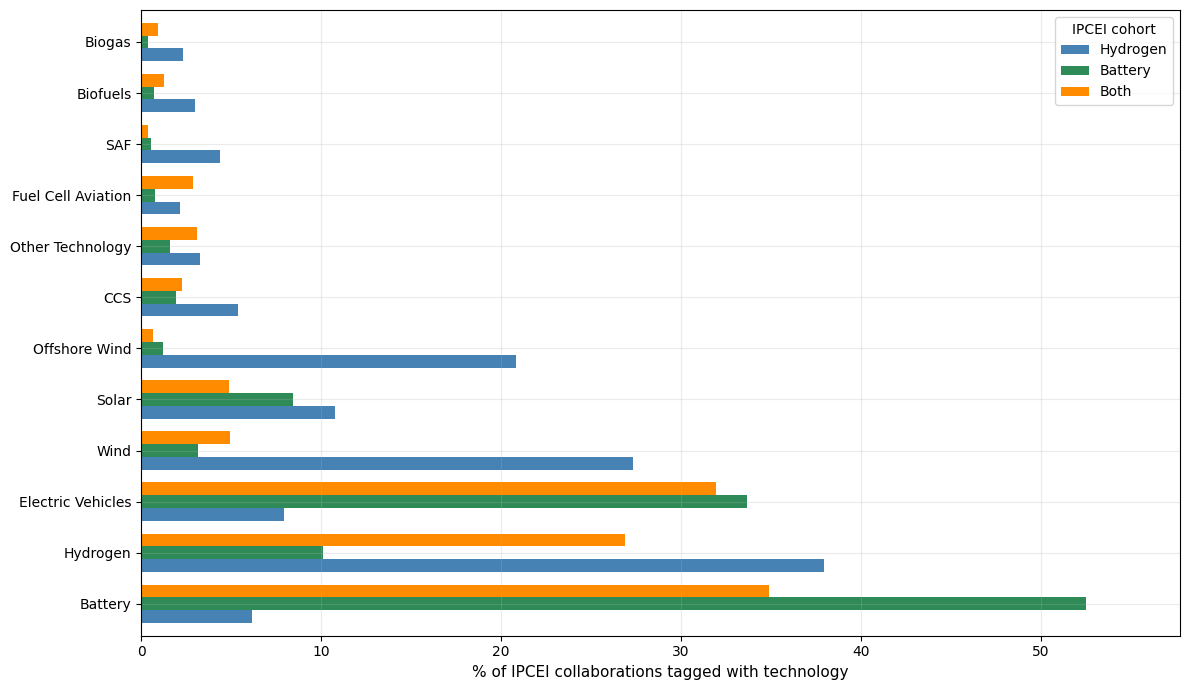


=== Technology Portfolio Summary ===

Top 5 technologies by IPCEI type:

Hydrogen:
  Hydrogen: 37.9%
  Wind: 27.3%
  Offshore Wind: 20.8%
  Solar: 10.8%
  Electric Vehicles: 7.9%

Battery:
  Battery: 52.5%
  Electric Vehicles: 33.7%
  Hydrogen: 10.1%
  Solar: 8.4%
  Wind: 3.2%

Both:
  Battery: 34.9%
  Electric Vehicles: 31.9%
  Hydrogen: 26.9%
  Wind: 4.9%
  Solar: 4.9%


In [23]:
# ============================================================
# Tech portfolio: What technologies do IPCEI firms collaborate on?
# ============================================================

# --- Inputs ---
fm = firm_master_ipcei.copy()
p = partnership_master_ipcei.copy()

# Technology columns
tech_cols = [
    'Biomass', 'Biofuels', 'Biogas', 'Wind', 'Offshore_Wind', 'Solar',
    'Concentrated_Solar', 'Waste_to_Heat', 'Direct_Air_Capture',
    'Carbon_Capture_And_Storage', 'Biochar', 'Carbon_Direct_Removal', 'BECCS',
    'Hydrogen', 'Nuclear_Energy', 'Nuclear_Fusion', 'Hydro_Energy', 'Geothermal',
    'Battery', 'Electric_Vehicles', 'Sustainable_Aviation_Fuels', 'E_Fuels',
    'Marine_Energy', 'Heat_Pumps', 'Railway', 'Electric_Shipping',
    'Electric_Aviation', 'Fuel_Cell_Aviation', 'Other_Technology'
]

# Keep only available columns
tech_cols = [c for c in tech_cols if c in p.columns]

# IPCEI firms
ipcei_firms = fm.loc[fm["treated_any"].fillna(0).astype(int) == 1,
                     ["Linkedin_name", "ipcei_types"]].copy()
ipcei_firms = ipcei_firms.dropna(subset=["Linkedin_name"]).drop_duplicates("Linkedin_name")

# Get IPCEI type
ipcei_firms["ipcei_type_group"] = (
    ipcei_firms["ipcei_types"].astype("string").str.lower().fillna("")
      .apply(lambda s: "Battery" if ("battery" in s and "hydrogen" not in s)
                      else ("Hydrogen" if ("hydrogen" in s and "battery" not in s)
                            else ("Both" if ("battery" in s and "hydrogen" in s)
                                  else "Unknown")))
)

# Prepare partnership data
tmp = p.copy()
for col in tech_cols:
    tmp[col] = pd.to_numeric(tmp[col], errors="coerce").fillna(0).astype(int)

# Endpoint table
src = tmp.rename(columns={"source": "Linkedin_name"})[["Linkedin_name", "collaboration_id"] + tech_cols]
tgt = tmp.rename(columns={"target": "Linkedin_name"})[["Linkedin_name", "collaboration_id"] + tech_cols]
endp = pd.concat([src, tgt], ignore_index=True).dropna(subset=["Linkedin_name"])

# Merge with IPCEI firms to filter
endp_ipcei = endp.merge(
    ipcei_firms[["Linkedin_name", "ipcei_type_group"]],
    on="Linkedin_name",
    how="inner"
)

# Aggregate: share of collaborations tagged with each tech, by IPCEI type
tech_shares = []

for ipcei_type in ["Hydrogen", "Battery", "Both"]:
    sub = endp_ipcei.loc[endp_ipcei["ipcei_type_group"] == ipcei_type].copy()
    if len(sub) == 0:
        continue

    n_total = sub["collaboration_id"].nunique()

    for tech in tech_cols:
        n_tech = sub.loc[sub[tech] == 1, "collaboration_id"].nunique()
        share_pct = (n_tech / n_total * 100) if n_total > 0 else 0

        tech_shares.append({
            "ipcei_type": ipcei_type,
            "technology": tech,
            "share_pct": share_pct,
            "n_collabs": n_tech,
        })

tech_df = pd.DataFrame(tech_shares)

# Focus on top technologies for cleaner visualization
# Get top 12 technologies overall
top_techs = (
    tech_df.groupby("technology")["n_collabs"].sum()
    .nlargest(12)
    .index.tolist()
)

tech_df_top = tech_df.loc[tech_df["technology"].isin(top_techs)].copy()

# Pivot for grouped bar chart
pivot = tech_df_top.pivot(index="technology", columns="ipcei_type", values="share_pct").fillna(0)

# Sort by overall prevalence
pivot["total"] = pivot.sum(axis=1)
pivot = pivot.sort_values("total", ascending=False).drop(columns=["total"])

# Reorder columns
col_order = [c for c in ["Hydrogen", "Battery", "Both"] if c in pivot.columns]
pivot = pivot[col_order]

# Clean up technology names for display
def clean_tech_name(s):
    s = s.replace("_", " ")
    # Abbreviations
    s = s.replace("Carbon Capture And Storage", "CCS")
    s = s.replace("Direct Air Capture", "DAC")
    s = s.replace("Sustainable Aviation Fuels", "SAF")
    return s

pivot.index = [clean_tech_name(x) for x in pivot.index]

# Plot
fig, ax = plt.subplots(figsize=(12, 7))

# Use your color scheme
color_map = {
    "Hydrogen": COLORS["three"][0],    # steelblue
    "Battery": COLORS["three"][1],     # seagreen
    "Both": COLORS["three"][2],        # darkorange
}

colors = [color_map.get(col, "grey") for col in pivot.columns]

pivot.plot(
    kind="barh",
    ax=ax,
    color=colors,
    width=0.75,
)

ax.set_xlabel("% of IPCEI collaborations tagged with technology", fontsize=11)
#ax.set_ylabel("Technology", fontsize=11)
ax.legend(title="IPCEI cohort", loc="upper right")

style_ax(ax)
ax.grid(axis="x", alpha=0.25)
ax.set_xlim(0, max(pivot.max()) * 1.1)

plt.tight_layout()

save_fig(fig, "descriptives_raw", "collaborations_ipcei_techportfolio_barchart")
plt.show()

# Print summary
print("\n=== Technology Portfolio Summary ===")
print(f"\nTop 5 technologies by IPCEI type:")
for ipcei_type in col_order:
    print(f"\n{ipcei_type}:")
    top5 = pivot[ipcei_type].nlargest(5)
    for tech, pct in top5.items():
        print(f"  {tech}: {pct:.1f}%")

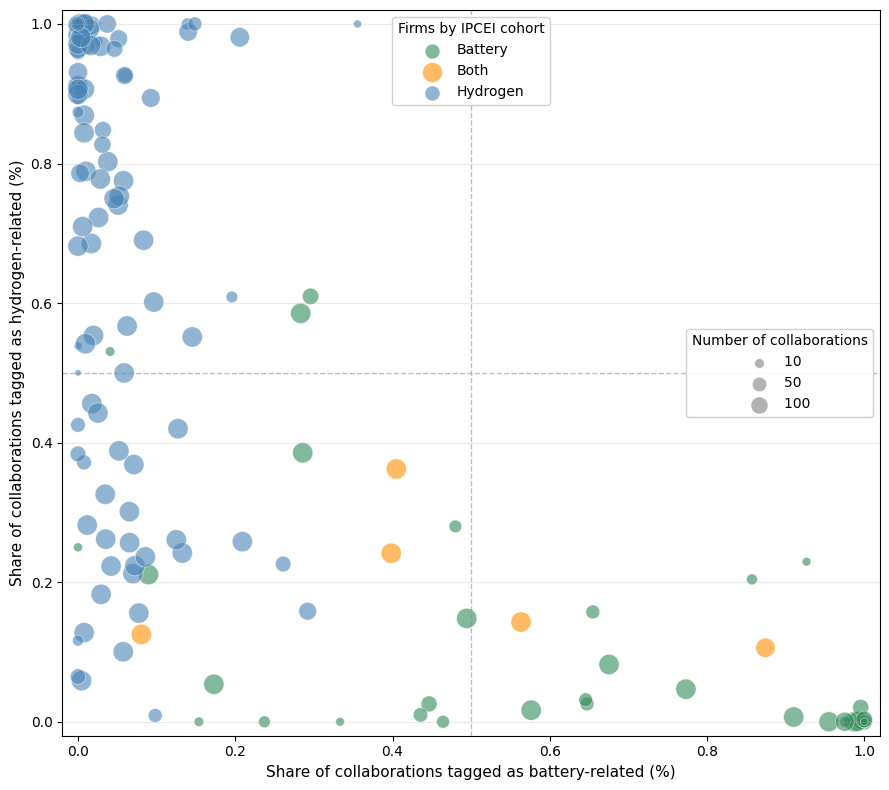


=== Tech Mix Analysis ===

Balanced firms (>40% in both H₂ and Battery): 0

H₂ specialists (>80% H₂ collabs): 50
Linkedin_name  n_collabs  share_hydrogen
   airliquide     1855.0        0.802590
  snam-s-p-a-     1131.0        0.906573
        lhyfe     1106.0        0.980272
     everfuel      510.0        0.984829
        mcphy      470.0        0.993137

Battery specialists (>80% Battery collabs): 17
               Linkedin_name  n_collabs  share_battery
                   northvolt      815.0       0.910217
acc-automotive-cells-company      250.0       0.987487
                     inobat1      192.0       0.955010
                     manz-ag      184.0       0.991448
                    varta-ag      158.0       0.975225

H₂ IPCEI firms with <30% H₂ collabs: 20
   Linkedin_name  n_collabs  share_hydrogen  share_battery
   totalenergies     5579.0        0.236236       0.085717
          orsted     4060.0        0.182675       0.029368
            rwe-     3753.0        0.256669 

In [24]:
# ============================================================
# Bubble chart: IPCEI firms' Hydrogen vs Battery collaboration mix
# ============================================================

# --- Input ---
fm = firm_master_ipcei.copy()
p = partnership_master_ipcei.copy()

# IPCEI firms
ipcei_firms = fm.loc[fm["treated_any"].fillna(0).astype(int) == 1,
                     ["Linkedin_name", "ipcei_types"]].copy()
ipcei_firms = ipcei_firms.dropna(subset=["Linkedin_name"]).drop_duplicates("Linkedin_name")

# Expand firm-tech exposure
cols = ["source", "target", "Hydrogen", "Battery", "collaboration_id"]
tmp = p[cols].copy()

tmp["Hydrogen"] = pd.to_numeric(tmp["Hydrogen"], errors="coerce").fillna(0).astype(int)
tmp["Battery"]  = pd.to_numeric(tmp["Battery"],  errors="coerce").fillna(0).astype(int)

# Endpoint table
src = tmp.rename(columns={"source": "Linkedin_name"})[["Linkedin_name", "collaboration_id", "Hydrogen", "Battery"]]
tgt = tmp.rename(columns={"target": "Linkedin_name"})[["Linkedin_name", "collaboration_id", "Hydrogen", "Battery"]]
endp = pd.concat([src, tgt], ignore_index=True).dropna(subset=["Linkedin_name", "collaboration_id"])

# Aggregate per firm
firm_tech = (
    endp.groupby("Linkedin_name", as_index=False)
        .agg(
            n_collabs=("collaboration_id", "nunique"),
            share_hydrogen=("Hydrogen", "mean"),
            share_battery=("Battery", "mean"),
        )
)

# Merge onto IPCEI firms
ip = ipcei_firms.merge(firm_tech, on="Linkedin_name", how="left")
ip[["n_collabs","share_hydrogen","share_battery"]] = \
    ip[["n_collabs","share_hydrogen","share_battery"]].fillna(0)

# IPCEI type group
ip["ipcei_type_group"] = (
    ip["ipcei_types"].astype("string").str.lower().fillna("")
      .apply(lambda s: "Battery" if ("battery" in s and "hydrogen" not in s)
                      else ("Hydrogen" if ("hydrogen" in s and "battery" not in s)
                            else ("Both" if ("battery" in s and "hydrogen" in s)
                                  else "Unknown")))
)

# --- Prepare plot data ---
plot_df = ip.loc[ip["n_collabs"] > 0].copy()

# Size scaling with better visual range
sizes = np.sqrt(plot_df["n_collabs"].clip(upper=200)) * 15

# --- Create figure ---
fig, ax = plt.subplots(figsize=(9, 8))

# Color map using your COLORS
color_map = {
    "Hydrogen": COLORS["three"][0],    # steelblue
    "Battery": COLORS["three"][1],     # seagreen
    "Both": COLORS["three"][2],        # darkorange
}

# Plot each group
for grp, sub in plot_df.groupby("ipcei_type_group"):
    if grp not in ["Hydrogen", "Battery", "Both"]:
        continue

    ax.scatter(
        sub["share_battery"],
        sub["share_hydrogen"],
        s=sizes.loc[sub.index],
        alpha=0.6,
        color=color_map.get(grp, "grey"),
        label=grp,
        edgecolors="white",
        linewidth=0.5,
    )

# Reference lines with annotations
ax.axvline(0.5, linestyle="--", linewidth=1, color="grey", alpha=0.5)
ax.axhline(0.5, linestyle="--", linewidth=1, color="grey", alpha=0.5)

# Formatting
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.02)
ax.set_xlabel("Share of collaborations tagged as battery-related (%)", fontsize=11)
ax.set_ylabel("Share of collaborations tagged as hydrogen-related (%)", fontsize=11)

style_ax(ax)
ax.legend(title="IPCEI program", loc="upper left", framealpha=0.9)

# Add size legend
size_values = [10, 50, 100]
size_legend_handles = [
    plt.scatter([], [], s=np.sqrt(v) * 15, c='grey', alpha=0.6, edgecolors="white", linewidth=0.5)
    for v in size_values
]
size_legend = ax.legend(
    size_legend_handles,
    [f"{v} " for v in size_values],
    title="Number of collaborations",
    loc="center right",
    framealpha=0.9,
    scatterpoints=1,
)
ax.add_artist(size_legend)

# Re-add the main legend (gets removed by second legend)
main_legend = ax.legend(
    *[ax.get_legend_handles_labels()[i] for i in [0, 1]],
    title="Firms by IPCEI cohort",
    loc="upper center",
    framealpha=0.9,
)

plt.tight_layout()

save_fig(fig, "descriptives_raw", "collaborations_ipcei_techportfolio_bubblechart")
plt.show()

# --- Analysis: identify interesting firms ---
print("\n=== Tech Mix Analysis ===")

# Balanced firms (high on both)
balanced = plot_df.loc[
    (plot_df["share_hydrogen"] > 0.4) & (plot_df["share_battery"] > 0.4)
].sort_values("n_collabs", ascending=False)

print(f"\nBalanced firms (>40% in both H₂ and Battery): {len(balanced)}")
if len(balanced) > 0:
    print(balanced[["Linkedin_name", "ipcei_types", "n_collabs",
                    "share_hydrogen", "share_battery"]].head(10).to_string(index=False))

# Specialists (>80% in one tech)
h2_specialists = plot_df.loc[
    (plot_df["share_hydrogen"] > 0.8) & (plot_df["ipcei_type_group"] == "Hydrogen")
].sort_values("n_collabs", ascending=False)

battery_specialists = plot_df.loc[
    (plot_df["share_battery"] > 0.8) & (plot_df["ipcei_type_group"] == "Battery")
].sort_values("n_collabs", ascending=False)

print(f"\nH₂ specialists (>80% H₂ collabs): {len(h2_specialists)}")
if len(h2_specialists) > 0:
    print(h2_specialists[["Linkedin_name", "n_collabs",
                          "share_hydrogen"]].head(5).to_string(index=False))

print(f"\nBattery specialists (>80% Battery collabs): {len(battery_specialists)}")
if len(battery_specialists) > 0:
    print(battery_specialists[["Linkedin_name", "n_collabs",
                               "share_battery"]].head(5).to_string(index=False))

# Misaligned firms (low on their IPCEI tech)
h2_misaligned = plot_df.loc[
    (plot_df["ipcei_type_group"] == "Hydrogen") & (plot_df["share_hydrogen"] < 0.3)
].sort_values("n_collabs", ascending=False)

battery_misaligned = plot_df.loc[
    (plot_df["ipcei_type_group"] == "Battery") & (plot_df["share_battery"] < 0.3)
].sort_values("n_collabs", ascending=False)

print(f"\nH₂ IPCEI firms with <30% H₂ collabs: {len(h2_misaligned)}")
if len(h2_misaligned) > 0:
    print(h2_misaligned[["Linkedin_name", "n_collabs", "share_hydrogen",
                         "share_battery"]].head(5).to_string(index=False))

print(f"\nBattery IPCEI firms with <30% Battery collabs: {len(battery_misaligned)}")
if len(battery_misaligned) > 0:
    print(battery_misaligned[["Linkedin_name", "n_collabs", "share_battery",
                              "share_hydrogen"]].head(5).to_string(index=False))

Collab types

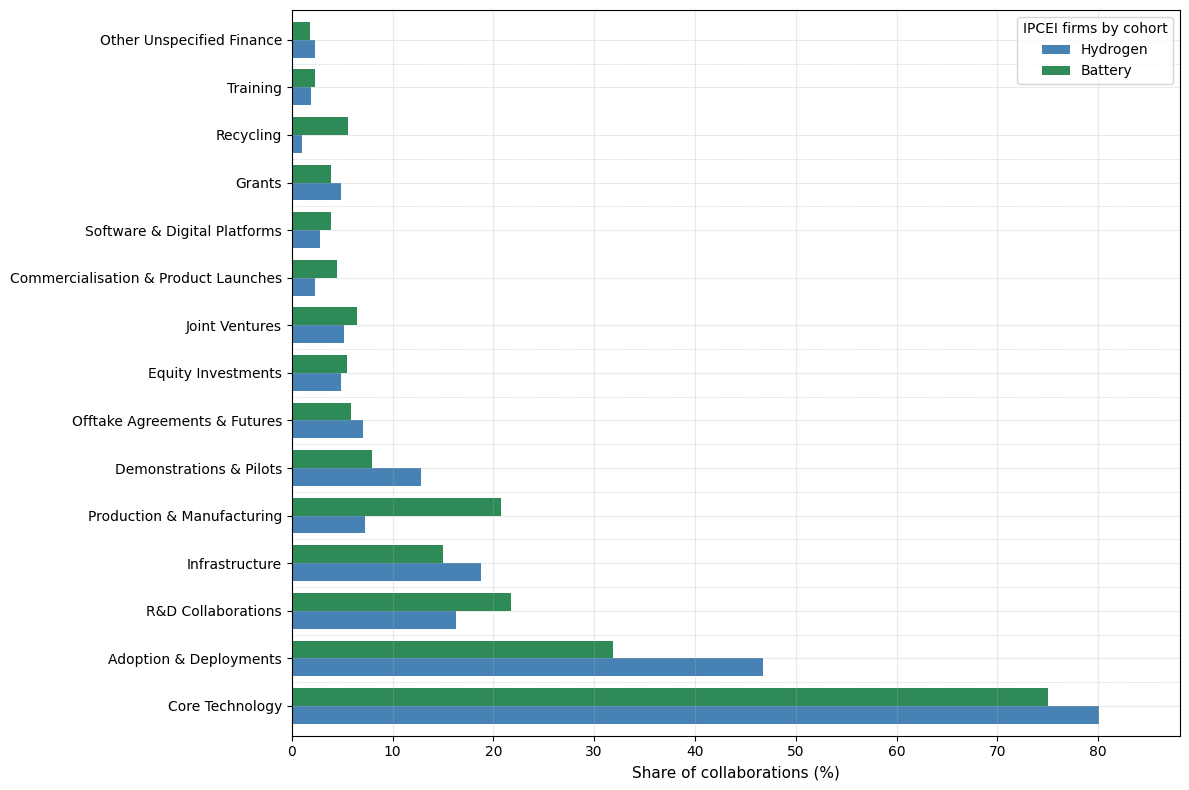


=== Collaboration Type Summary ===

Top 5 collaboration types by IPCEI type:

Hydrogen:
  Core Technology: 80.1%
  Adoption & Deployments: 46.7%
  Infrastructure: 18.8%
  R&D Collaborations: 16.3%
  Demonstrations & Pilots: 12.8%

Battery:
  Core Technology: 75.0%
  Adoption & Deployments: 31.8%
  R&D Collaborations: 21.7%
  Production & Manufacturing: 20.8%
  Infrastructure: 15.0%


By category:
category    Activity stage  Finance  Partnership form  Value chain
ipcei_type                                                        
Battery               13.4      3.1               2.0         16.8
Both                  14.8      2.4               1.2         17.0
Hydrogen              13.5      3.2               2.0         17.3


R&D vs Commercialization focus:
  Hydrogen: R&D=16.3%, Comm=2.3%, Ratio=7.04
  Battery: R&D=21.7%, Comm=4.4%, Ratio=4.90


In [26]:
# ============================================================
# Collaboration types: What activities do IPCEI firms engage in?
# ============================================================

# --- Inputs ---
fm = firm_master_ipcei.copy()
p = partnership_master_ipcei.copy()

# Collaboration type columns (grouped by category)
activity_cols = [
    'r_and_d_collaborations',
    'demonstrations_and_pilots',
    'commercialisation_and_product_launches',
    'production_and_manufacturing',
    'offtake_agreements_and_futures',
    'adoption_and_deployments',
    'operations_and_maintenance',
]

finance_cols = [
    'grants',
    'equity_investments',
    'loans',
    'other_unspecified_finance',
]

partnership_cols = [
    'spin_offs',
    'joint_ventures',
    'incubators_and_accelerator_programs',
    'certification_and_approvals',
    'training',
]

value_chain_cols = [
    'core_technology',
    'infrastructure',
    'software_and_digital_platforms',
    'raw_materials',
    'recycling',
    'other_complementary_activities',
]

# Combine all
all_collab_cols = activity_cols + finance_cols + partnership_cols + value_chain_cols

# Keep only available columns
all_collab_cols = [c for c in all_collab_cols if c in p.columns]

# IPCEI firms
ipcei_firms = fm.loc[fm["treated_any"].fillna(0).astype(int) == 1,
                     ["Linkedin_name", "ipcei_types"]].copy()
ipcei_firms = ipcei_firms.dropna(subset=["Linkedin_name"]).drop_duplicates("Linkedin_name")

# Get IPCEI type
ipcei_firms["ipcei_type_group"] = (
    ipcei_firms["ipcei_types"].astype("string").str.lower().fillna("")
      .apply(lambda s: "Battery" if ("battery" in s and "hydrogen" not in s)
                      else ("Hydrogen" if ("hydrogen" in s and "battery" not in s)
                            else ("Both" if ("battery" in s and "hydrogen" in s)
                                  else "Unknown")))
)

# Prepare partnership data
tmp = p.copy()
for col in all_collab_cols:
    tmp[col] = pd.to_numeric(tmp[col], errors="coerce").fillna(0).astype(int)

# Endpoint table
src = tmp.rename(columns={"source": "Linkedin_name"})[["Linkedin_name", "collaboration_id"] + all_collab_cols]
tgt = tmp.rename(columns={"target": "Linkedin_name"})[["Linkedin_name", "collaboration_id"] + all_collab_cols]
endp = pd.concat([src, tgt], ignore_index=True).dropna(subset=["Linkedin_name"])

# Merge with IPCEI firms
endp_ipcei = endp.merge(
    ipcei_firms[["Linkedin_name", "ipcei_type_group"]],
    on="Linkedin_name",
    how="inner"
)

# Aggregate: share of collaborations with each type, by IPCEI type
collab_shares = []

for ipcei_type in ["Hydrogen", "Battery", "Both"]:
    sub = endp_ipcei.loc[endp_ipcei["ipcei_type_group"] == ipcei_type].copy()
    if len(sub) == 0:
        continue

    n_total = sub["collaboration_id"].nunique()

    for collab_type in all_collab_cols:
        n_type = sub.loc[sub[collab_type] == 1, "collaboration_id"].nunique()
        share_pct = (n_type / n_total * 100) if n_total > 0 else 0

        # Determine category
        if collab_type in activity_cols:
            category = "Activity stage"
        elif collab_type in finance_cols:
            category = "Finance"
        elif collab_type in partnership_cols:
            category = "Partnership form"
        else:
            category = "Value chain"

        collab_shares.append({
            "ipcei_type": ipcei_type,
            "collab_type": collab_type,
            "category": category,
            "share_pct": share_pct,
            "n_collabs": n_type,
        })

collab_df = pd.DataFrame(collab_shares)

# Get top collaboration types overall
top_collab_types = (
    collab_df.groupby("collab_type")["n_collabs"].sum()
    .nlargest(15)
    .index.tolist()
)

collab_df_top = collab_df.loc[collab_df["collab_type"].isin(top_collab_types)].copy()

# Pivot
pivot = collab_df_top.pivot(index="collab_type", columns="ipcei_type", values="share_pct").fillna(0)

# Sort by overall prevalence
pivot["total"] = pivot.sum(axis=1)
pivot = pivot.sort_values("total", ascending=False).drop(columns=["total"])

# Reorder columns
col_order = [c for c in ["Hydrogen", "Battery"] if c in pivot.columns]
pivot = pivot[col_order]

# Clean up names
def clean_collab_name(s):
    s = s.replace("_", " ").replace(" and ", " & ")
    # Capitalize properly
    words = s.split()
    # Keep certain words lowercase
    lower_words = {"and", "of", "the", "to"}
    cleaned = " ".join([
        w if w.lower() in lower_words else w.capitalize()
        for w in words
    ])
    # Abbreviations
    cleaned = cleaned.replace("R & D", "R&D")
    return cleaned

pivot.index = [clean_collab_name(x) for x in pivot.index]

# Add category labels for grouping
category_map = dict(zip(collab_df_top["collab_type"], collab_df_top["category"]))
category_map = {clean_collab_name(k): v for k, v in category_map.items()}

# --- Plot ---
fig, ax = plt.subplots(figsize=(12, 8))

# Color scheme
color_map = {
    "Hydrogen": COLORS["two"][0],    # steelblue
    "Battery": COLORS["two"][1],     # seagreen
}

colors = [color_map.get(col, "grey") for col in pivot.columns]

pivot.plot(
    kind="barh",
    ax=ax,
    color=colors,
    width=0.75,
)

ax.set_xlabel("Share of collaborations (%)", fontsize=11)
#ax.set_ylabel("Collaboration type", fontsize=11)
ax.legend(title="IPCEI firms by cohort", loc="upper right")

style_ax(ax)
ax.grid(axis="x", alpha=0.25)
ax.set_xlim(0, max(pivot.max()) * 1.1)

# Add category separators (optional visual enhancement)
prev_category = None
y_pos = len(pivot) - 0.5
for idx, (collab_type, row) in enumerate(pivot.iterrows()):
    current_category = category_map.get(collab_type, "")
    if prev_category and current_category != prev_category:
        ax.axhline(y_pos, color='grey', linestyle='--', linewidth=0.5, alpha=0.3)
    prev_category = current_category
    y_pos -= 1

plt.tight_layout()

save_fig(fig, "descriptives_raw", "collaborations_ipcei_activitytype_barchart")
plt.show()

# --- Summary statistics ---
print("\n=== Collaboration Type Summary ===")
print(f"\nTop 5 collaboration types by IPCEI type:")
for ipcei_type in col_order:
    print(f"\n{ipcei_type}:")
    top5 = pivot[ipcei_type].nlargest(5)
    for collab_type, pct in top5.items():
        print(f"  {collab_type}: {pct:.1f}%")

# Category breakdown
print("\n\nBy category:")
cat_summary = collab_df.groupby(["ipcei_type", "category"])["share_pct"].mean().unstack(fill_value=0)
print(cat_summary.round(1).to_string())

# Compare R&D vs commercialization
if "R&D Collaborations" in pivot.index and "Commercialisation & Product Launches" in pivot.index:
    print("\n\nR&D vs Commercialization focus:")
    for ipcei_type in col_order:
        rd_share = pivot.loc["R&D Collaborations", ipcei_type] if "R&D Collaborations" in pivot.index else 0
        comm_share = pivot.loc["Commercialisation & Product Launches", ipcei_type] if "Commercialisation & Product Launches" in pivot.index else 0
        ratio = rd_share / comm_share if comm_share > 0 else float('inf')
        print(f"  {ipcei_type}: R&D={rd_share:.1f}%, Comm={comm_share:.1f}%, Ratio={ratio:.2f}")

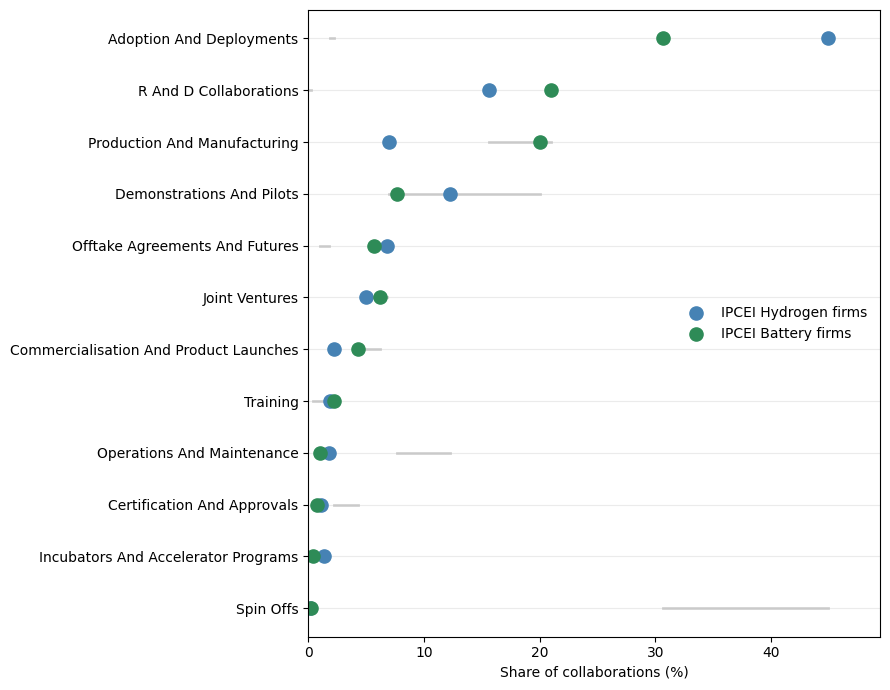

In [27]:
# ============================================================
# Collaboration activities: Activity stages & partnership forms
# ============================================================

fm = firm_master_ipcei.copy()
p = partnership_master_ipcei.copy()

activity_cols = [
    'r_and_d_collaborations',
    'demonstrations_and_pilots',
    'commercialisation_and_product_launches',
    'production_and_manufacturing',
    'offtake_agreements_and_futures',
    'adoption_and_deployments',
    'operations_and_maintenance',
]

partnership_cols = [
    'spin_offs',
    'joint_ventures',
    'incubators_and_accelerator_programs',
    'certification_and_approvals',
    'training',
]

collab_type_cols = [c for c in activity_cols + partnership_cols if c in p.columns]

# IPCEI firms
ipcei_firms = fm.loc[
    fm["treated_any"].fillna(0).astype(int) == 1,
    ["Linkedin_name", "ipcei_types"]
].dropna(subset=["Linkedin_name"]).drop_duplicates("Linkedin_name")

ipcei_firms["ipcei_type_group"] = (
    ipcei_firms["ipcei_types"].astype("string").str.lower().fillna("")
    .apply(lambda s: "Battery" if ("battery" in s and "hydrogen" not in s)
           else ("Hydrogen" if ("hydrogen" in s and "battery" not in s)
                 else "Other"))
)

tmp = p.copy()
for col in collab_type_cols:
    tmp[col] = pd.to_numeric(tmp[col], errors="coerce").fillna(0).astype(int)

src = tmp.rename(columns={"source": "Linkedin_name"})[
    ["Linkedin_name", "collaboration_id"] + collab_type_cols
]
tgt = tmp.rename(columns={"target": "Linkedin_name"})[
    ["Linkedin_name", "collaboration_id"] + collab_type_cols
]

endp = pd.concat([src, tgt], ignore_index=True).dropna(subset=["Linkedin_name"])

endp_ipcei = endp.merge(
    ipcei_firms[["Linkedin_name", "ipcei_type_group"]],
    on="Linkedin_name",
    how="inner"
)

records = []

for t in ["Hydrogen", "Battery"]:
    sub = endp_ipcei[endp_ipcei["ipcei_type_group"] == t]
    for c in collab_type_cols:
        n = sub.loc[sub[c] == 1, "collaboration_id"].nunique()
        records.append({"ipcei_type": t, "category": c, "n": n})

df = pd.DataFrame(records)

df["share"] = df.groupby("ipcei_type")["n"].transform(lambda x: 100 * x / x.sum())

pivot = df.pivot(index="category", columns="ipcei_type", values="share").reset_index()

pivot["avg"] = pivot[["Hydrogen", "Battery"]].mean(axis=1)
pivot = pivot.sort_values("avg")

# --- Cleveland plot ---
fig, ax = plt.subplots(figsize=(9, 7))
y = np.arange(len(pivot))

for i, row in pivot.iterrows():
    ax.plot(
        [row["Hydrogen"], row["Battery"]],
        [y[i], y[i]],
        color="lightgray",
        linewidth=2,
        zorder=1
    )

ax.scatter(pivot["Hydrogen"], y,
           color=COLORS["three"][0], s=90, label="IPCEI Hydrogen firms", zorder=2)

ax.scatter(pivot["Battery"], y,
           color=COLORS["three"][1], s=90, label="IPCEI Battery firms", zorder=2)

ax.set_yticks(y)
ax.set_yticklabels(pivot["category"].str.replace("_", " ").str.title())

ax.set_xlabel("Share of collaborations (%)")
ax.set_xlim(0, pivot[["Hydrogen", "Battery"]].max().max() * 1.1)

style_ax(ax)
ax.legend(loc="center right", frameon=False)

plt.tight_layout()
save_fig(fig, "descriptives_raw", "collaborations_ipcei_activitytype_clevelandplot")
plt.show()

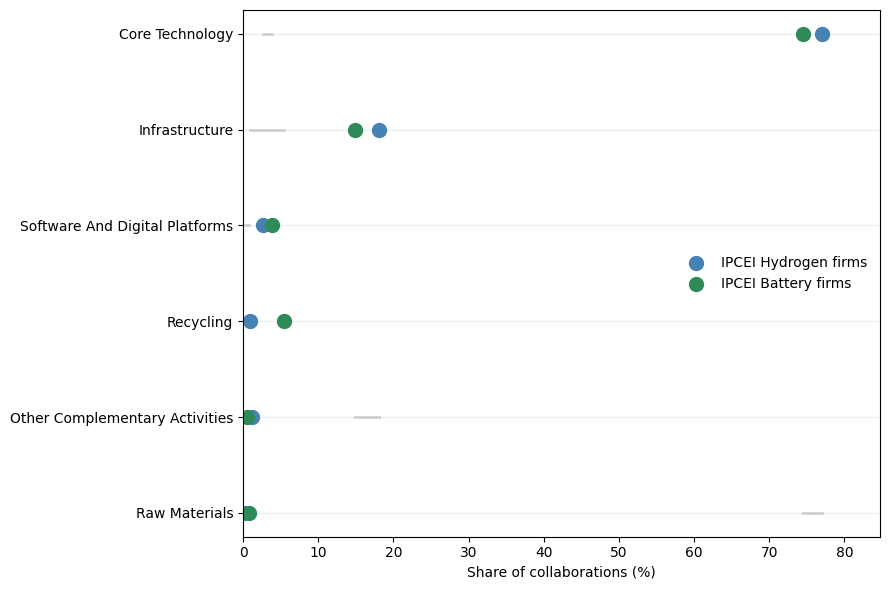

In [28]:
# ============================================================
# Value chain focus — Cleveland plot
# ============================================================

fm = firm_master_ipcei.copy()
p = partnership_master_ipcei.copy()

value_chain_cols = [
    'core_technology',
    'infrastructure',
    'software_and_digital_platforms',
    'raw_materials',
    'recycling',
    'other_complementary_activities',
]

value_chain_cols = [c for c in value_chain_cols if c in p.columns]

ipcei_firms = fm.loc[
    fm["treated_any"].fillna(0).astype(int) == 1,
    ["Linkedin_name", "ipcei_types"]
].dropna(subset=["Linkedin_name"]).drop_duplicates("Linkedin_name")

ipcei_firms["ipcei_type_group"] = (
    ipcei_firms["ipcei_types"].astype("string").str.lower().fillna("")
    .apply(lambda s: "Battery" if ("battery" in s and "hydrogen" not in s)
           else ("Hydrogen" if ("hydrogen" in s and "battery" not in s)
                 else "Other"))
)

tmp = p.copy()
for col in value_chain_cols:
    tmp[col] = pd.to_numeric(tmp[col], errors="coerce").fillna(0).astype(int)

src = tmp.rename(columns={"source": "Linkedin_name"})[
    ["Linkedin_name", "collaboration_id"] + value_chain_cols
]
tgt = tmp.rename(columns={"target": "Linkedin_name"})[
    ["Linkedin_name", "collaboration_id"] + value_chain_cols
]

endp = pd.concat([src, tgt], ignore_index=True).dropna(subset=["Linkedin_name"])

endp_ipcei = endp.merge(
    ipcei_firms[["Linkedin_name", "ipcei_type_group"]],
    on="Linkedin_name",
    how="inner"
)

records = []

for t in ["Hydrogen", "Battery"]:
    sub = endp_ipcei[endp_ipcei["ipcei_type_group"] == t]
    for c in value_chain_cols:
        n = sub.loc[sub[c] == 1, "collaboration_id"].nunique()
        records.append({"ipcei_type": t, "category": c, "n": n})

df = pd.DataFrame(records)

df["share"] = df.groupby("ipcei_type")["n"].transform(lambda x: 100 * x / x.sum())

pivot = df.pivot(index="category", columns="ipcei_type", values="share").reset_index()

pivot["avg"] = pivot[["Hydrogen", "Battery"]].mean(axis=1)
pivot = pivot.sort_values("avg")

# --- Cleveland plot ---
fig, ax = plt.subplots(figsize=(9, 6))
y = np.arange(len(pivot))

for i, row in pivot.iterrows():
    ax.plot(
        [row["Hydrogen"], row["Battery"]],
        [y[i], y[i]],
        color="lightgray",
        linewidth=2,
        zorder=1
    )

ax.scatter(pivot["Hydrogen"], y,
           color=COLORS["three"][0], s=100, label="IPCEI Hydrogen firms", zorder=2)

ax.scatter(pivot["Battery"], y,
           color=COLORS["three"][1], s=100, label="IPCEI Battery firms", zorder=2)

ax.set_yticks(y)
ax.set_yticklabels(pivot["category"].str.replace("_", " ").str.title())

ax.set_xlabel("Share of collaborations (%)")
ax.set_xlim(0, pivot[["Hydrogen", "Battery"]].max().max() * 1.1)

style_ax(ax)
ax.legend(loc="center right", frameon=False)

plt.tight_layout()
save_fig(fig, "descriptives_raw", "collaborations_ipcei_valuechain_clevelandplot")
plt.show()
